In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

# import sys
# from pathlib import Path

# sys.path.append(str(Path.cwd().parent / "scripts"))

import plotting_utils as pu
import directories as dirs

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import numpy as np
import pandas as pd
import arviz as az
import ast

import h5py
import glob

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import ringdown as rd

results:   0%|          | 0/5 [00:00<?, ?it/s]

In [3]:
pu.remnant_ds.m, pu.remnant_ds.chi

(np.float64(72.55320774907538), np.float64(0.8015415596433029))

In [4]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

from plotting_utils import * 

import pickle
import matplotlib.gridspec as gridspec

from concurrent.futures import ProcessPoolExecutor, as_completed

In [5]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times New Roman"],  # Use Times New Roman font
    # Optional: Add packages via the preamble if needed
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",

    # --- Global Font Size Configurations ---
    "font.size": 12,          # Base font size for all text
    "axes.labelsize": 14,     # Size of x and y labels
    "axes.titlesize": 16,     # Size of plot title
    "xtick.labelsize": 12,    # Size of x-axis tick marks
    "ytick.labelsize": 12,    # Size of y-axis tick marks
    "legend.fontsize": 12,    # Size of legends
})

In [6]:
def _compute_loo(args):
    combo, s, result, fcut, gcut = args

    if (fcut is not None) or (gcut is not None):
        result._generate_whitened_residuals()
        result.stack(sample=("chain", "draw"))

        if fcut is not None:
            sub_mode = len(combo.split('+')) - 1
            if '<' in fcut:
                mask = result.posterior.f[:,sub_mode] < float(fcut[1:])
            else:
                mask = result.posterior.f[:,sub_mode] > float(fcut[1:])
        if gcut is not None:
            sub_mode = len(combo.split('+')) - 1
            if '<' in gcut:
                mask = result.posterior.g[:,sub_mode] < float(gcut[1:])
            else:
                mask = result.posterior.g[:,sub_mode] > float(gcut[1:])

        result = result.isel(sample=mask.values)

    return combo, s, result.loo

class Remnant(remnant_ds):
    def __init__(self, config_path):
        config = rd.utils.load_config(config_path)
        if 'remnant_nr' in config.keys():
            self.m = float(config['remnant_nr']['mf_true'])
            self.chi = float(config['remnant_nr']['cf_true'])
        elif 'remnant_ds' in config.keys():
            self.m = float(config['remnant_ds']['mf_true'])
            self.chi = float(config['remnant_ds']['cf_true'])
        else:
            self.m = remnant_ds.m
            self.chi = remnant_ds.chi

In [7]:
a = 2 - 1j*3
a, np.conj(a)

((2-3j), np.complex128(2+3j))

In [18]:
def cross_corr(mode1, mode2, m, chi, tauM):
    f1, tau1 = rd.qnms.get_ftau(M=m, chi=chi, l=int(mode1[0]), m=int(mode1[1]), n=int(mode1[2]))
    f2, tau2 = rd.qnms.get_ftau(M=m, chi=chi, l=int(mode2[0]), m=int(mode2[1]), n=int(mode2[2]))
    g1, g2 = 1/tau1, 1/tau2

    w1 = 2*np.pi*f1 - 1j*g1
    w2 = 2*np.pi*f2 - 1j*g2

    TM = rd.qnms.T_MSUN * m
    tau = tauM * TM

    num = -1j * np.exp(-1j * w2 * tau) * 2 * np.sqrt(g1*g2)
    denom = w2 - np.conj(w1)

    return num/denom

Text(0, 0.5, '$\\left| (h_{220} \\star h_{\\mathrm{bonus}})(\\tau) \\right|$')

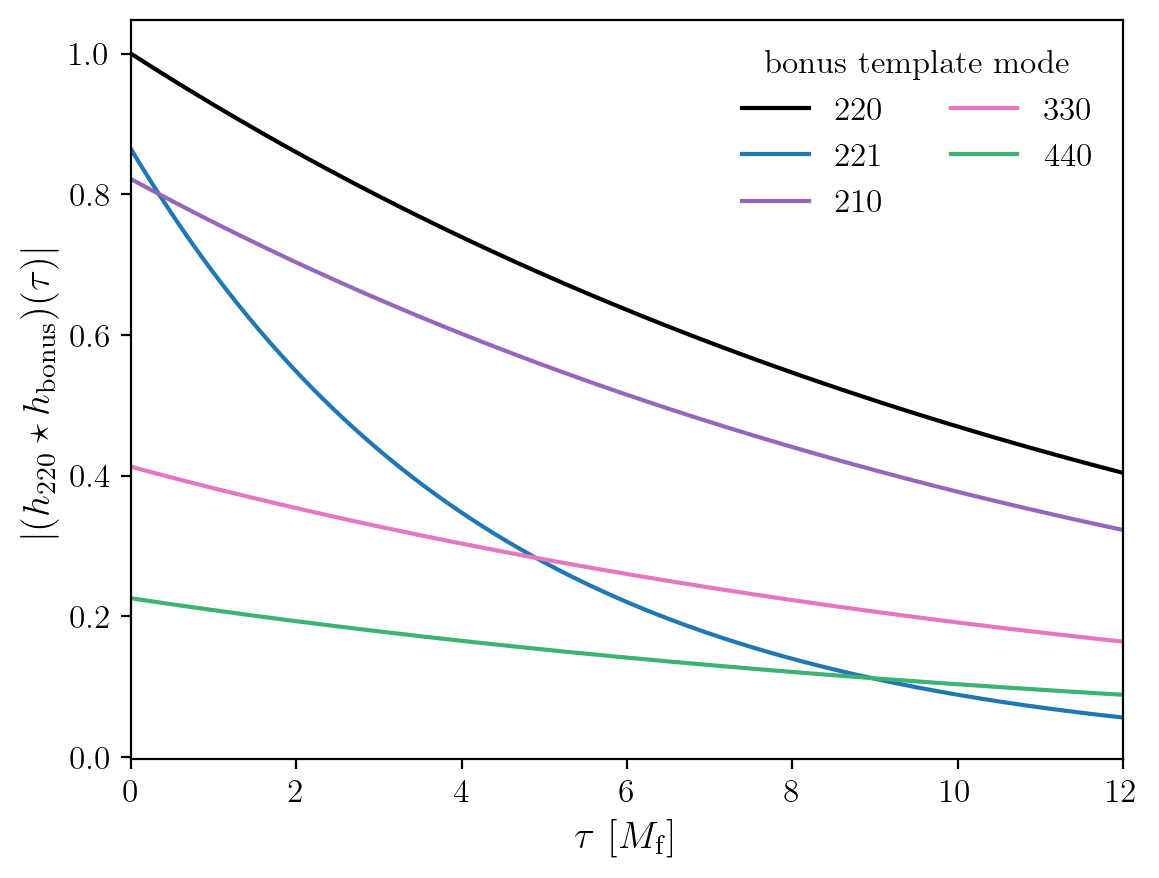

In [59]:
tauM = np.linspace(0, 13, 1000)
dtau = tauM[1] - tauM[0]

modes2 = ['220', '221', '210', '330', '440']
for mode2, col in zip(modes2, ['k', 'tab:blue', 'tab:purple', 'tab:pink', 'mediumseagreen']):
    Rcross = cross_corr('220', mode2, pu.remnant_ds.m, pu.remnant_ds.chi, tauM)
    plt.plot(tauM, np.abs(Rcross), color=col, label=mode2)

plt.legend(title='bonus template mode', ncol=2, frameon=False)
plt.xlim(0, 12)

plt.xlabel('$\\tau$ [$M_{\mathrm{f}}$]')
plt.ylabel('$\left| (h_{220} \star h_{\mathrm{bonus}})(\\tau) \\right|$')

/mnt/home/nkhusid/.virtualenvs/rd_igwn/lib/python3.11/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/mnt/home/nkhusid/.virtualenvs/rd_igwn/lib/python3.11/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Text(0, 0.5, '$(h_{220} \\star h_{\\mathrm{bonus}})(\\tau)$')

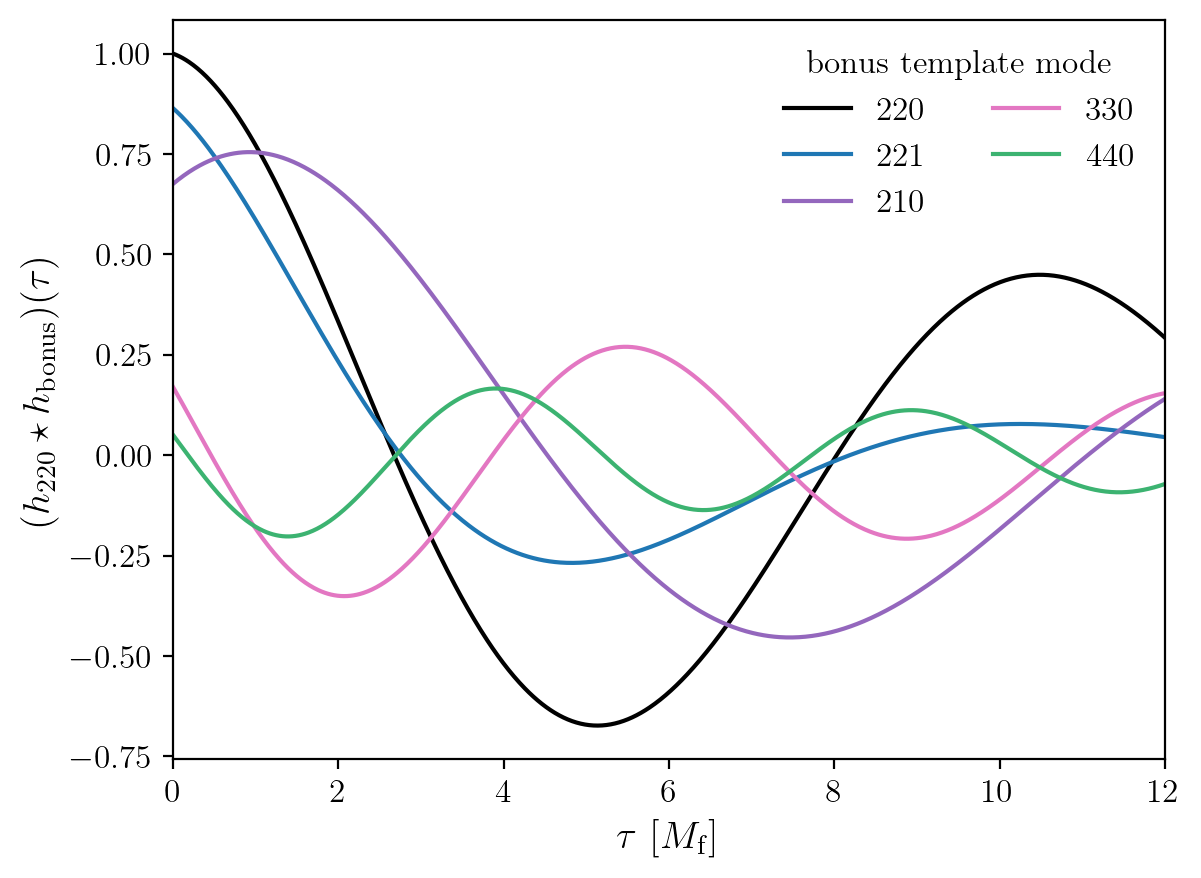

In [62]:
tauM = np.linspace(0, 13, 1000)
dtau = tauM[1] - tauM[0]

modes2 = ['220', '221', '210', '330', '440']
for mode2, col in zip(modes2, ['k', 'tab:blue', 'tab:purple', 'tab:pink', 'mediumseagreen']):
    Rcross = cross_corr('220', mode2, pu.remnant_ds.m, pu.remnant_ds.chi, tauM)
    plt.plot(tauM, Rcross, color=col, label=mode2)

plt.legend(title='bonus template mode', ncol=2, frameon=False)
plt.xlim(0, 12)

plt.xlabel('$\\tau$ [$M_{\mathrm{f}}$]')
plt.ylabel('$(h_{220} \star h_{\mathrm{bonus}})(\\tau)$')

/mnt/home/nkhusid/.virtualenvs/rd_igwn/lib/python3.11/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


Text(0, 0.5, '$\\left| (h_{220} \\star h_{\\mathrm{bonus}})(\\tau) \\right|$')

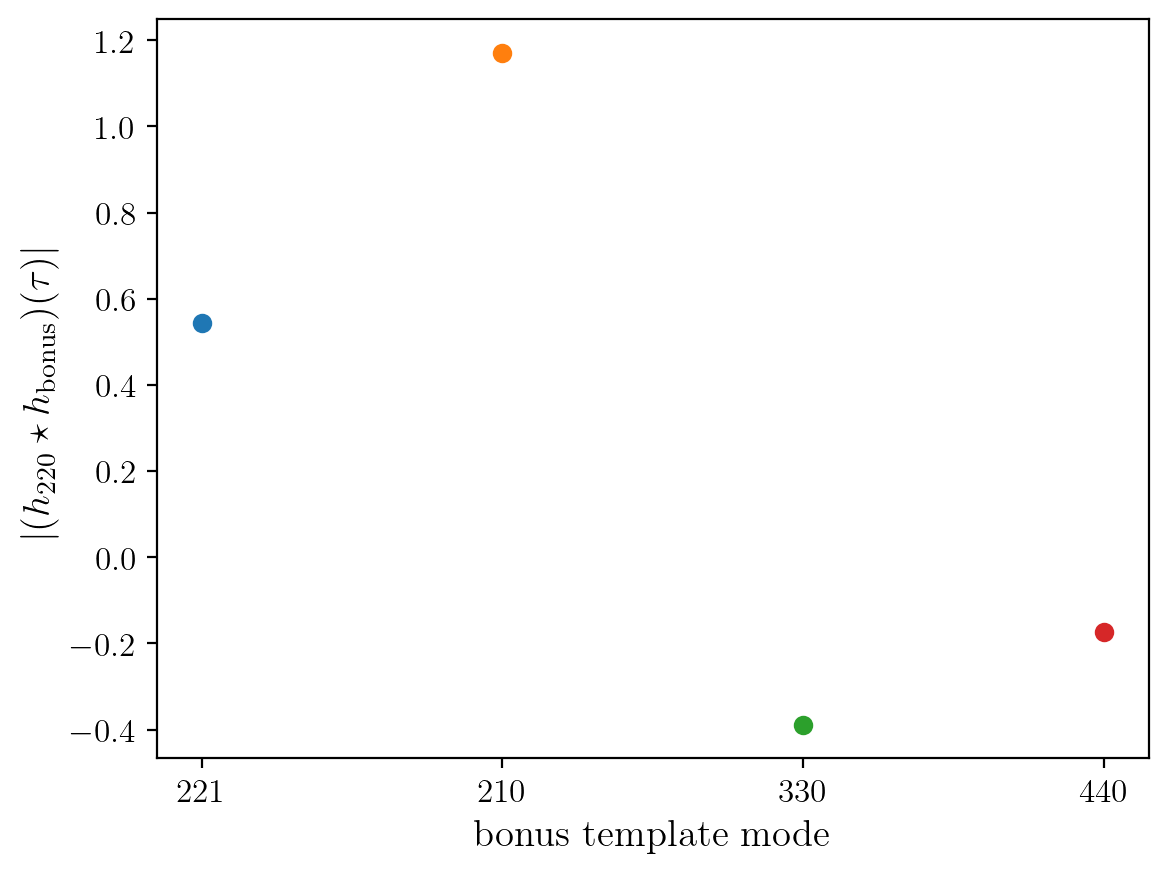

In [76]:
tauM = np.linspace(0, 1000, int(1e6))
dtau = tauM[1] - tauM[0]

modes2 = ['221', '210', '330', '440']
for mode2 in modes2:
    Rcross = cross_corr('220', mode2, pu.remnant_ds.m, pu.remnant_ds.chi, tauM)
    tau_cross = np.trapezoid(Rcross, tauM, dx=dtau)
    plt.scatter(mode2, tau_cross, label=mode2)

# plt.legend(title='bonus template mode', ncol=2, frameon=False)
# plt.xlim(0, 12)

# plt.xlabel('$\\tau$ [$M_{\mathrm{f}}$]')
plt.xlabel('bonus template mode')
plt.ylabel('$\left| (h_{220} \star h_{\mathrm{bonus}})(\\tau) \\right|$')

Text(0, 0.5, '$\\left| (h_{220} \\star h_{\\mathrm{bonus}})(\\tau) \\right|$')

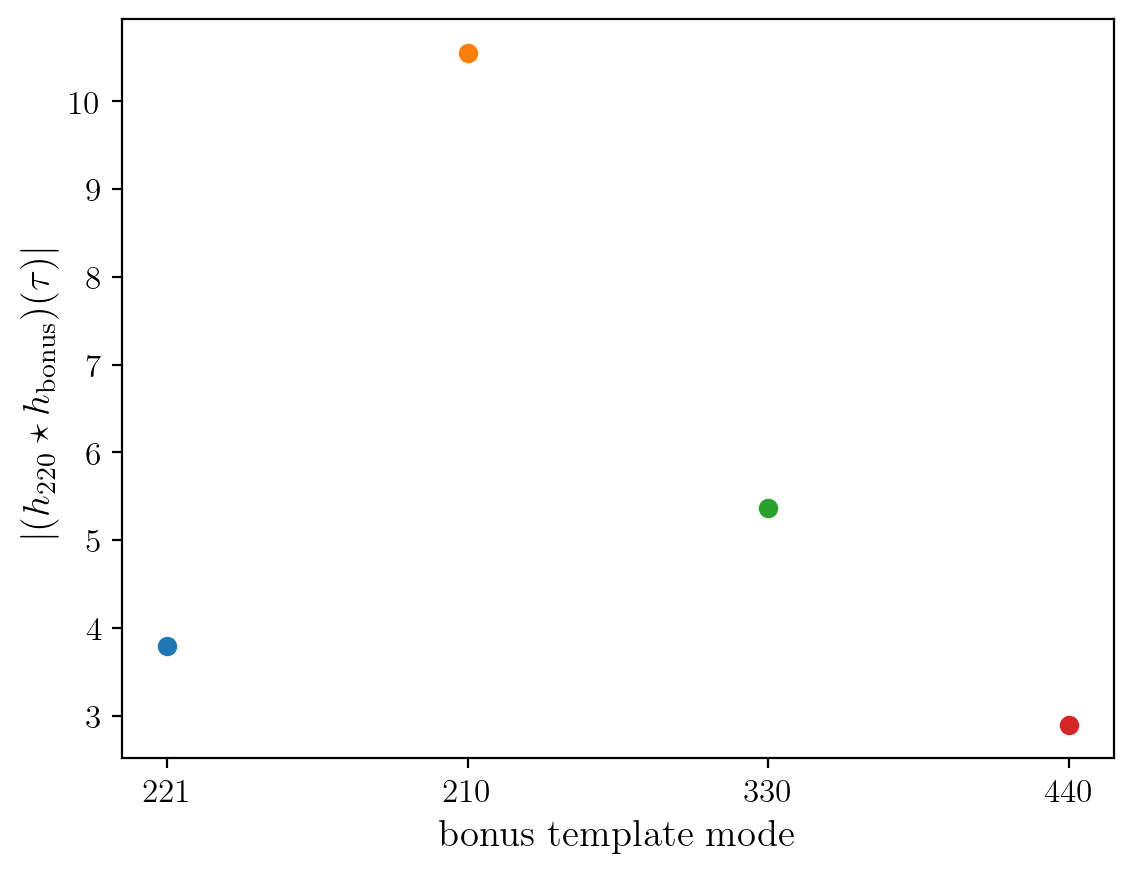

In [73]:
tauM = np.linspace(0, 1000, int(1e6))
dtau = tauM[1] - tauM[0]

modes2 = ['221', '210', '330', '440']
for mode2 in modes2:
    Rcross = cross_corr('220', mode2, pu.remnant_ds.m, pu.remnant_ds.chi, tauM)
    tau_cross = np.trapezoid(abs(Rcross), tauM, dx=dtau)
    plt.scatter(mode2, tau_cross, label=mode2)

# plt.legend(title='bonus template mode', ncol=2, frameon=False)
# plt.xlim(0, 12)

# plt.xlabel('$\\tau$ [$M_{\mathrm{f}}$]')
plt.xlabel('bonus template mode')
plt.ylabel('$\left| (h_{220} \star h_{\mathrm{bonus}})(\\tau) \\right|$')

/mnt/home/nkhusid/.virtualenvs/rd_igwn/lib/python3.11/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/mnt/home/nkhusid/.virtualenvs/rd_igwn/lib/python3.11/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Text(0, 0.5, '$\\int d\\tau \\, (h_{220} \\star h_{\\mathrm{bonus}})(\\tau)$')

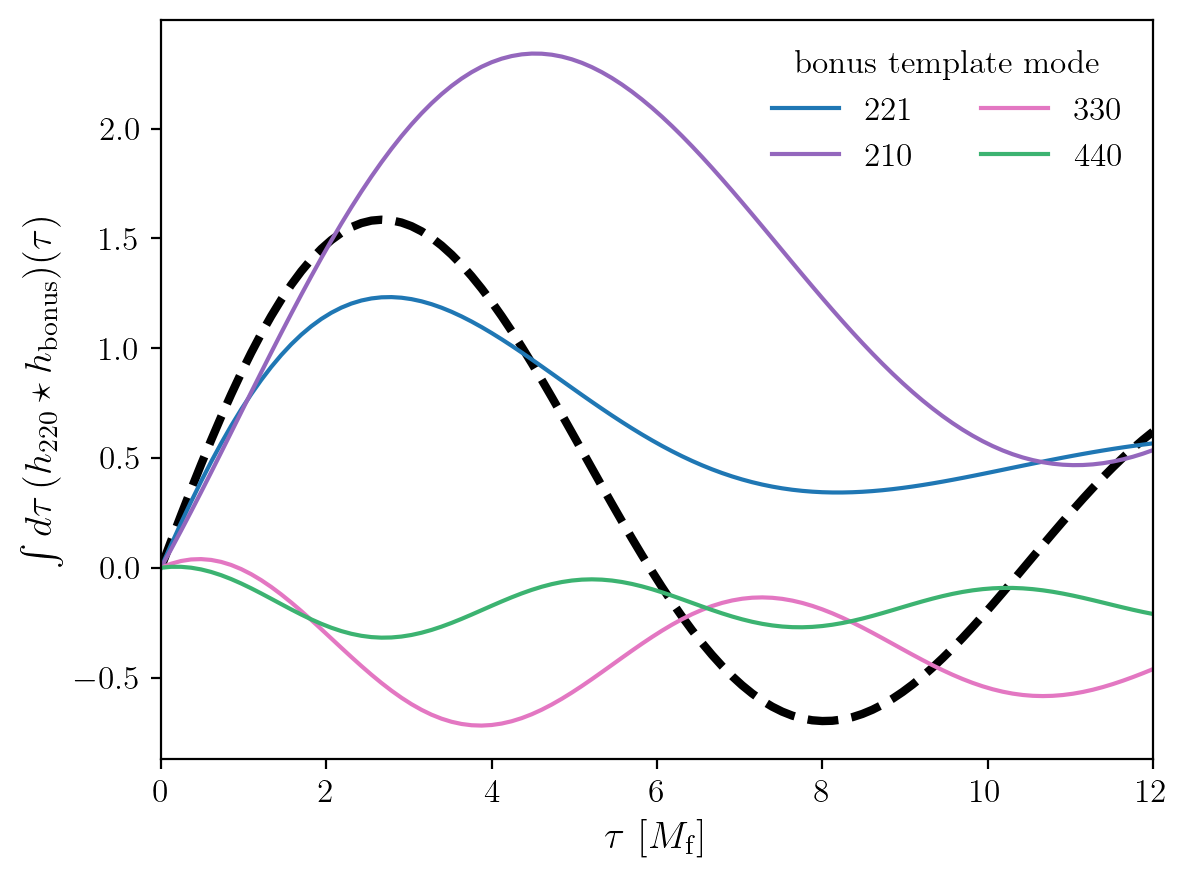

In [66]:
taus = np.linspace(0, 12, 100)

modes2 = ['220', '221', '210', '330', '440']
for mode2, col in zip(modes2, ['k', 'tab:blue', 'tab:purple', 'tab:pink', 'mediumseagreen']):
    T_crosses = []
    for tau in taus:
        tauM = np.linspace(0, tau, int(1e6))
        dtau = tauM[1] - tauM[0]
        Rcross = cross_corr('220', mode2, pu.remnant_ds.m, pu.remnant_ds.chi, tauM)
        tau_cross = np.trapezoid(Rcross, tauM, dx=dtau)
        T_crosses.append(tau_cross)
    if mode2 == '220':
        plt.plot(taus, T_crosses, ls='--', color=col, lw=3)
    else:
        plt.plot(taus, T_crosses, color=col, label=mode2)

plt.legend(title='bonus template mode', ncol=2, frameon=False)
plt.xlim(0, 12)

plt.xlabel('$\\tau$ [$M_{\mathrm{f}}$]')
# plt.xlabel('bonus template mode')
plt.ylabel('$\int d\\tau \, (h_{220} \star h_{\mathrm{bonus}})(\\tau)$')

Text(0, 0.5, '$\\int d\\tau \\, (h_{220} \\star h_{\\mathrm{bonus}})(\\tau)$')

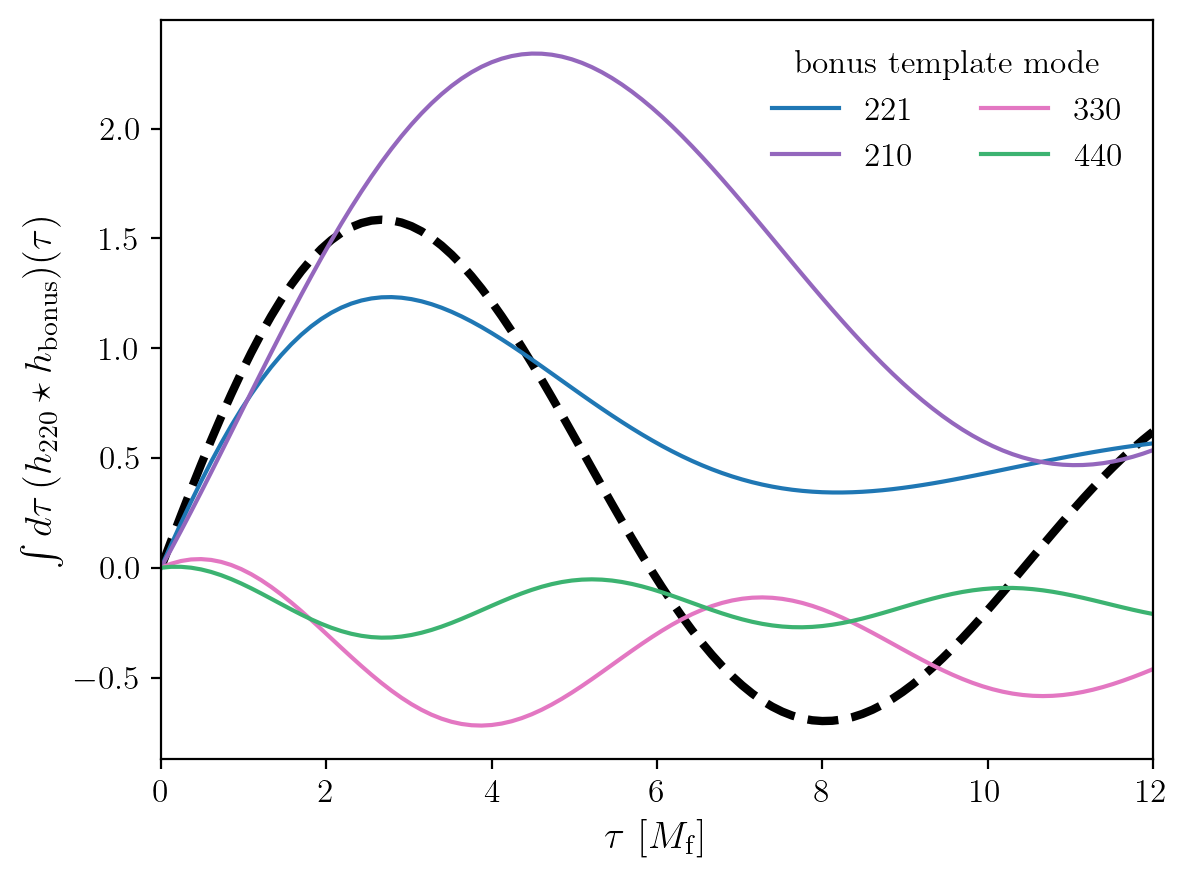

In [69]:
taus = np.linspace(0, 12, 100)

modes2 = ['220', '221', '210', '330', '440']
for mode2, col in zip(modes2, ['k', 'tab:blue', 'tab:purple', 'tab:pink', 'mediumseagreen']):
    T_crosses = []
    for tau in taus:
        tauM = np.linspace(0, tau, int(1e6))
        dtau = tauM[1] - tauM[0]
        Rcross = cross_corr('220', mode2, pu.remnant_ds.m, pu.remnant_ds.chi, tauM)
        tau_cross = np.trapezoid(Rcross, tauM, dx=dtau)
        T_crosses.append(np.real(tau_cross))
    if mode2 == '220':
        plt.plot(taus, T_crosses, ls='--', color=col, lw=3)
    else:
        plt.plot(taus, T_crosses, color=col, label=mode2)

plt.legend(title='bonus template mode', ncol=2, frameon=False)
plt.xlim(0, 12)

plt.xlabel('$\\tau$ [$M_{\mathrm{f}}$]')
# plt.xlabel('bonus template mode')
plt.ylabel('$\int d\\tau \, (h_{220} \star h_{\mathrm{bonus}})(\\tau)$')

Text(0, 0.5, '$\\int d\\tau \\, \\left| (h_{220} \\star h_{\\mathrm{bonus}})(\\tau) \\right|$')

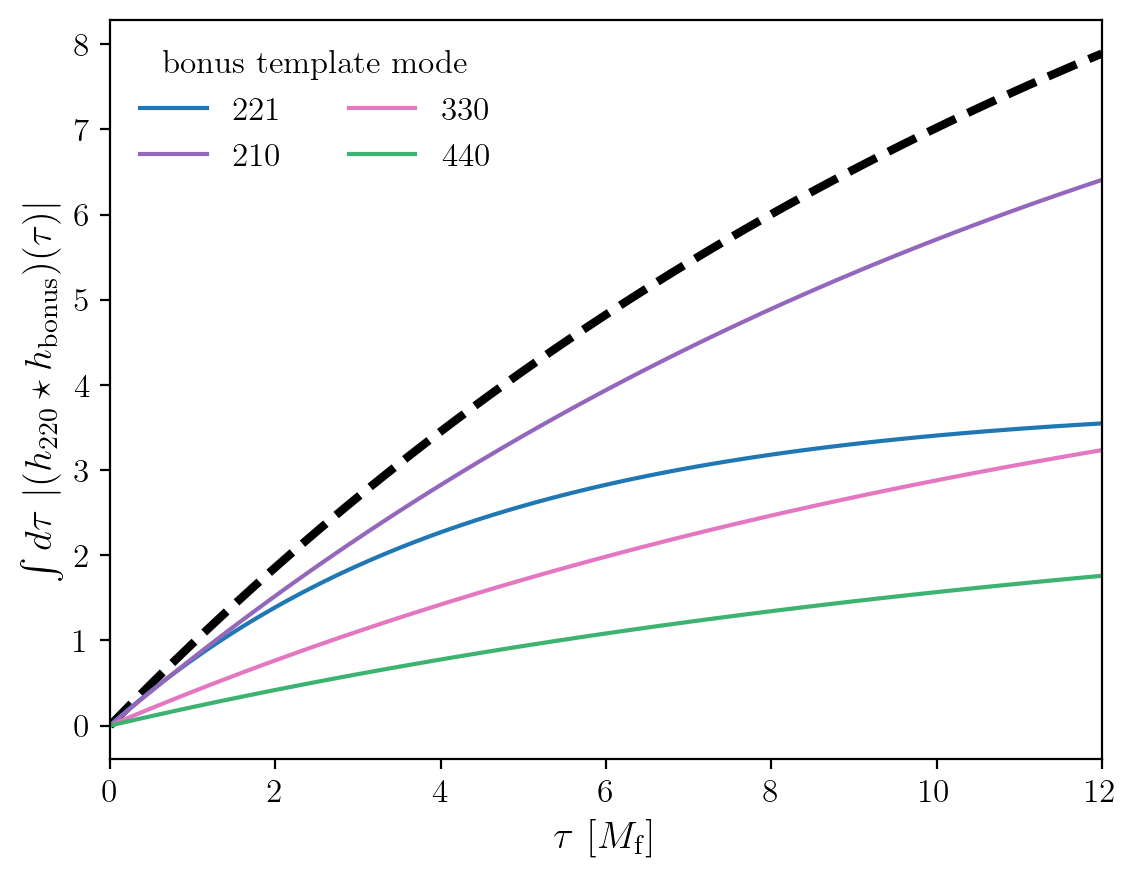

In [67]:
taus = np.linspace(0, 12, 100)

modes2 = ['220', '221', '210', '330', '440']
for mode2, col in zip(modes2, ['k', 'tab:blue', 'tab:purple', 'tab:pink', 'mediumseagreen']):
    T_crosses = []
    for tau in taus:
        tauM = np.linspace(0, tau, int(1e6))
        dtau = tauM[1] - tauM[0]
        Rcross = cross_corr('220', mode2, pu.remnant_ds.m, pu.remnant_ds.chi, tauM)
        tau_cross = np.trapezoid(np.abs(Rcross), tauM, dx=dtau)
        T_crosses.append(tau_cross)
    if mode2 == '220':
        plt.plot(taus, T_crosses, color=col, ls='--', lw=3)
    else:
        plt.plot(taus, T_crosses, color=col, label=mode2)

plt.legend(title='bonus template mode', ncol=2, frameon=False)
plt.xlim(0, 12)

plt.xlabel('$\\tau$ [$M_{\mathrm{f}}$]')
# plt.xlabel('bonus template mode')
plt.ylabel('$\int d\\tau \, \left| (h_{220} \star h_{\mathrm{bonus}})(\\tau) \\right|$')

In [6]:
def main(path: str, model: list, tref: int = 0, sub_lo: int = None, sub_hi: int = None, a_idx: list = None, comp: bool = True, cache: bool = True, fcut: str = None, gcut: str = None, comp_model: str = None, save: bool = True, figaxs: tuple = None):

    # parser = argparse.ArgumentParser()

    # parser.add_argument('--path', type=str, required=True, help="Path to subdir for injection type, e.g. 'DS/220' or 'SXS_BBH_1155/mtot330'")

    # parser.add_argument('--model', nargs='+', required=True, type=str, help='Modes in QNM model whose results to plot, e.g. --model 220 210')

    # parser.add_argument('--tref', required=False, default=0, type=int, help='Analysis time from which to project amplitude posterior, e.g. --tref -3. Default is --tref 0.')

    # parser.add_argument('--no-comp', action='store_false', dest='comp', default=True, help='Do not generate LOO model comparison plot.')

    # parser.add_argument('--no-cache', action='store_false', dest='cache', default=True, help='No LOO cache, compute from scratch.')

    # parser.add_argument('--fcut', type=str, default=None)

    # parser.add_argument('--gcut', type=str, default=None)

    # args = parser.parse_args()

    modes = model
    combo = '+'.join(modes)
    # fcut = args.fcut
    # gcut = args.gcut
    ifo = 'H1'

    if 'DS' in path:
        morph = 'dfpre-0.5_dtaupre0'
    else:
        morph = f'{path.split("/")[-1]}_inclined'
    inj_path = glob.glob(str(dirs.datdir / 'injections' / path / f'*ppSNR20_{morph}_{ifo}.hdf5'))
    inj = pd.read_hdf(inj_path[0], key=ifo)

    if 'DS' in path:
        injtype = 'DS_GW250114Kerr'
    else:
        injtype = f'{path.split("/")[0]}'

    # single_ds = rd.Result.from_netcdf(str(dirs.resdir / path / f'220_{injtype}_fmin10Hz_ppSNR20_{morph}' / 'engine' / f'{inj_ds.t0:.6f}' / 'result.nc'))

    run = dirs.resdir / path / f'{combo}_{injtype}_fmin10Hz_ppSNR20_{morph}'
    config_ref = run / 'config.ini'
    remnant = Remnant(str(config_ref))
    mref = remnant.m
    cref = remnant.chi

    coll = rd.ResultCollection.from_netcdf(str(run / 'engine' / '*' / 'result.nc'))
    coll.reindex_by_t0(reference_time=inj_ds.t0, reference_mass=mref, decimals=0)
    df = coll.get_parameter_dataframe(ndraw=4000, progress=True, prng=13)
    
    if fcut is not None:
        sub_mode = combo.split('+')[-1]
        if '<' in fcut:
            df = df[df[f'f_{sub_mode}'] < float(fcut[1:])]
        else:
            df = df[df[f'f_{sub_mode}'] > float(fcut[1:])]
    if gcut is not None:
        sub_mode = combo.split('+')[-1]
        if '<' in gcut:
            df = df[df[f'g_{sub_mode}'] < float(gcut[1:])]
        else:
            df = df[df[f'g_{sub_mode}'] > float(gcut[1:])]
    # dfs[combo] = df
    sub = False
    if sub_lo is not None:
        df_sub = df[df['run'] >= sub_lo]
        sub = True
    if sub_hi is not None:
        df_sub = df[df['run'] <= sub_hi]
        sub = True

    psd_path = coll[0].config['acf']['path'][ifo]
    fit = rd.Fit()
    fit.load_data({ifo: inj_path[0]})
    fit.set_target(inj_ds.t0, inj_ds.ra, inj_ds.dec, inj_ds.psi, duration=0.5)
    TM = rd.qnms.T_MSUN * mref

    cachewinjdir = dirs.datdir / 'injections' / path
    if not cachewinjdir.exists():
        cachewinjdir.mkdir(parents=True)
    cachewinj_path = cachewinjdir / f'winj_ppSNR20_{morph}.pkl'

    if cachewinj_path.exists():
        print(f'Loading cached whitened injection from {cachewinj_path}...')
        with open(cachewinj_path, 'rb') as f:
            winj = pickle.load(f)
    else:
        print('No cached whitened injection, whitening now...')

        fit.load_acfs(from_psd=True, path={ifo: psd_path})
        winj = fit.whiten({ifo: inj})

        with open(cachewinj_path, 'wb') as f:
            pickle.dump(winj, f)
        print(f'Saved whitened injection to {cachewinj_path}')

    if figaxs is not None:
        fig, (ax_top, ax1, ax2, ax3) = figaxs
    else:
        fig = plt.figure(figsize=(10, 5))
        gs = gridspec.GridSpec(2, 3, figure=fig, height_ratios=[1, 1.5])  
        # fig.subplots_adjust(wspace=0.5)

        ax_top = fig.add_subplot(gs[0, :])
        ax1 = fig.add_subplot(gs[1, 0])
        ax2 = fig.add_subplot(gs[1, 1])
        ax3 = fig.add_subplot(gs[1, 2])

        pos = ax3.get_position()
        ax3.set_position([
            pos.x0 + 0.05,
            pos.y0,
            pos.width * 0.85,
            pos.height
        ])

        plt.tight_layout()

        for ax in fig.axes:
            ax.tick_params(axis='both', which='both', direction='in')

    # fig.align_ylabels()

    ### plotting injection
    times = (inj.index.values - fit.start_times[ifo]) / TM
    l, = ax_top.plot(times, winj[ifo], color='k', lw=4)
    # ax_top.plot(times[(times >= 0) & (times <= 0.5/TM)], single_ds.whitened_data[0], lw=5, color='gray', alpha=0.5)
    # ax_top.plot(times[(times >= 0) & (times <= 0.5/TM)], np.quantile(single_ds.whitened_templates[0,:,:], q=0.5, axis=-1), lw=2.5, color='red', alpha=0.5, ls='--')
    ax_top.axvline(0, color='k', ls=':', lw=1)
    # ax_top.axhline(0, color='red', ls=':', lw=1)
    ax_top.axvspan(-12, 12, color='gray', alpha=0.1, lw=0)
    ax_top.set_xlim(-43, 43)
    ax_top.set_xlabel('$t - t_{\mathrm{peak}}$ [$t_{M_{\mathrm{f}}}$]')
    ax_top.set_ylabel('Whitened H1 strain')

    ax_top.xaxis.set_label_coords(0.5, -0.05, transform=ax_top.transAxes)
    l.axes.spines['bottom'].set_position(('data', 0))
    l.axes.spines['top'].set_visible(False)
    l.axes.spines['right'].set_visible(False)

    ### plotting m-chi
    print('Plotting m-chi...')

    if sub:
        plot_mfcf_man(df_sub, mref, cref, ax1, legend=True, **dict(palette='Oranges_r'))
    else:
        plot_mfcf_man(df_sub, mref, cref, ax1, legend=True, **dict(palette='Oranges_r'))

    ### plotting amps
    print('Plotting amps...')

    modecol_map = {'221': 'blue',
                   '210': 'purple',
                   '330': 'pink',
                   '222': 'red',
                   '220': 'gray'}
    if a_idx is not None:
        a_modes = [modes[i] for i in a_idx]
    else:
        a_modes = modes[-1]

    for m, a_mode in enumerate(a_modes):
        acol = modecol_map[a_mode]
        clevs = [0.95, 0.68]
        a_df = get_projection(df, a_mode, tref)

        shift = np.linspace(-0.3, 0.3, len(a_modes))[m]
        a_scale = 1e-21
        plot_scan(df, a_mode, clevs, f'tab:{acol}', ax2, marker='o', shift=shift, a_scale=a_scale)
        plot_projection(a_df, [min(clevs)], ax2, color=f'tab:{acol}', a_scale=a_scale)
        ax2.axvline(tref+shift, ls=':', lw=1, color=f'tab:{acol}')

        ax2.set_xlabel('$t - t_{\\mathrm{peak}}$ [$t_{M_f}$]')
        ax2.set_xticks(np.arange(-12, 15, 3))
        ax2.set_xlim(-12.5, 12.5)

        ax2.set_ylabel(f'$A_{{\mathrm{{\ell |m| n}}}}$ [$10^{{{int(np.log10(a_scale))}}}$]')
        a_max = np.quantile(df[df['run'] == tref][f"a_{a_mode}"].values, 0.55) * 2
        # ax2.set_ylim(0, np.ceil(a_max / a_scale))
        ax2.set_ylim(0, 10)

    ### plotting loos
    if comp:
        print('Plotting LOOs...')

        # Loading results from all models
        loo_colls = {combo: coll}
        if comp_model is not None:
            extra_combos = glob.glob(str(dirs.resdir / path / f'{comp_model}_{injtype}_fmin10Hz_ppSNR20_{morph}'))    
        else:
            extra_combos = glob.glob(str(dirs.resdir / path / f'*_{injtype}_fmin10Hz_ppSNR20_{morph}'))
        for run_path in extra_combos:
            extra_combo = run_path.split('/')[-1].split('_')[0]
            if extra_combo not in loo_colls.keys():
                print(f'Adding {extra_combo} to model comparison...')
                coll = rd.ResultCollection.from_netcdf(f'{run_path}/engine/*/result.nc')
                coll.reindex_by_t0(reference_time=inj_ds.t0, reference_mass=mref, decimals=0)
                loo_colls[extra_combo] = coll

        cachedir = dirs.datdir / 'injections' / path / 'comp'
        if not cachedir.exists():
            cachedir.mkdir(parents=True)
        cache_path = cachedir / f'loo_comp_dict_ppSNR20_{morph}.pkl'

        if cache_path.exists() & cache:
            print(f'Loading cached LOO results from {cache_path}...')
            with open(cache_path, 'rb') as f:
                loo_results = pickle.load(f)

        else:
            print('No cached LOO results, computing now...')

            # Parallelizing
            max_workers = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count()))
            tasks = [(combo, s, r.idx[s], fcut, gcut) for combo, r in loo_colls.items() for s in df['run'].unique()]
            loo_results = {}   # (key, value) = ((combo, s), ELPDData)
            with ProcessPoolExecutor(max_workers=max_workers) as executor:
                futures = {executor.submit(_compute_loo, t): t for t in tasks}
                for fut in as_completed(futures):
                    cb, s, loo_res = fut.result()
                    loo_results[(cb, s)] = loo_res

            with open(cache_path, 'wb') as f:
                pickle.dump(loo_results, f)
            print(f'Saved LOO results to {cache_path}')

        starts = df['run'].unique()
        loo_dict = pd.DataFrame({combo: [loo_results[(combo, s)].elpd_loo for s in starts] for combo in loo_colls},
                                index=np.array(starts))

        model_dfs = []
        for s in loo_dict.index:
            model_df = az.compare({combo: loo_results[(combo, s)] for combo in loo_colls}, ic='loo')
            model_df['$t - t_{\\mathrm{peak}}$ [$t_{M_f}$]'] = s
            model_dfs.append(model_df)

        comp_df = pd.concat(model_dfs, ignore_index=False)
        comp_df['model'] = comp_df.index

        palette = sns.color_palette('Greens_r', n_colors=len(comp_df['model'].unique())+1)
        markers = ['H', '^', 'X', '*', 'P', '>']
        marker_map = dict(zip(comp_df['model'].unique(), markers))
        sns.scatterplot(comp_df, x='$t - t_{\\mathrm{peak}}$ [$t_{M_f}$]', y='elpd_loo', hue='model', style='model',
                        markers=marker_map, s=150, ax=ax3, palette=palette)
        for i in range(len(comp_df)):
            if comp_df.iloc[i]['rank'] != 0:
                _, caps, bars = ax3.errorbar(x=comp_df.iloc[i]['$t - t_{\\mathrm{peak}}$ [$t_{M_f}$]'], y=comp_df.iloc[i]['elpd_loo'], yerr=comp_df.iloc[i]['se'], lw=3.5, c=palette[list(comp_df.index.unique()).index(comp_df.index[i])], capsize=None, alpha=0.75, zorder=-1)
                for bar in bars:
                    bar.set_capstyle('round')
        ax3.set_ylabel('LOO')
        # ax3.set_yscale('symlog', linthresh=1)
        # ax3.axhline(0, c='gray', ls='--', zorder=-1)
        # ax3.grid(alpha=0.2)
        # ax3.set_yticks(np.arange(0, 10))
        # ax3.set_ylim(-40)

    if save:
        if 'DS' in path:
            plt.savefig(str(dirs.figdir / 'paper' / f'inj{path.split("/")[-1]}_fit{combo}_unit.pdf'), bbox_inches='tight')
        else:
            plt.savefig(str(dirs.figdir / 'paper' / f'inj{path.replace("/", "_")}_fit{combo}_unit.pdf'), bbox_inches='tight')

    return fig, (ax_top, ax1, ax2, ax3)

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/DS/220+330/winj_ppSNR20_dfpre-0.5_dtaupre0.pkl...
Plotting m-chi...
Plotting amps...
Plotting LOOs...
Adding 220+330 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached LOO results from /mnt/home/nkhusid/spec_inj/data/injections/DS/220+330/comp/loo_comp_dict_ppSNR20_dfpre-0.5_dtaupre0.pkl...


/tmp/ipykernel_473060/3494710029.py:234: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(comp_df, x='$t - t_{\\mathrm{peak}}$ [$t_{M_f}$]', y='elpd_loo', hue='model', style='model',


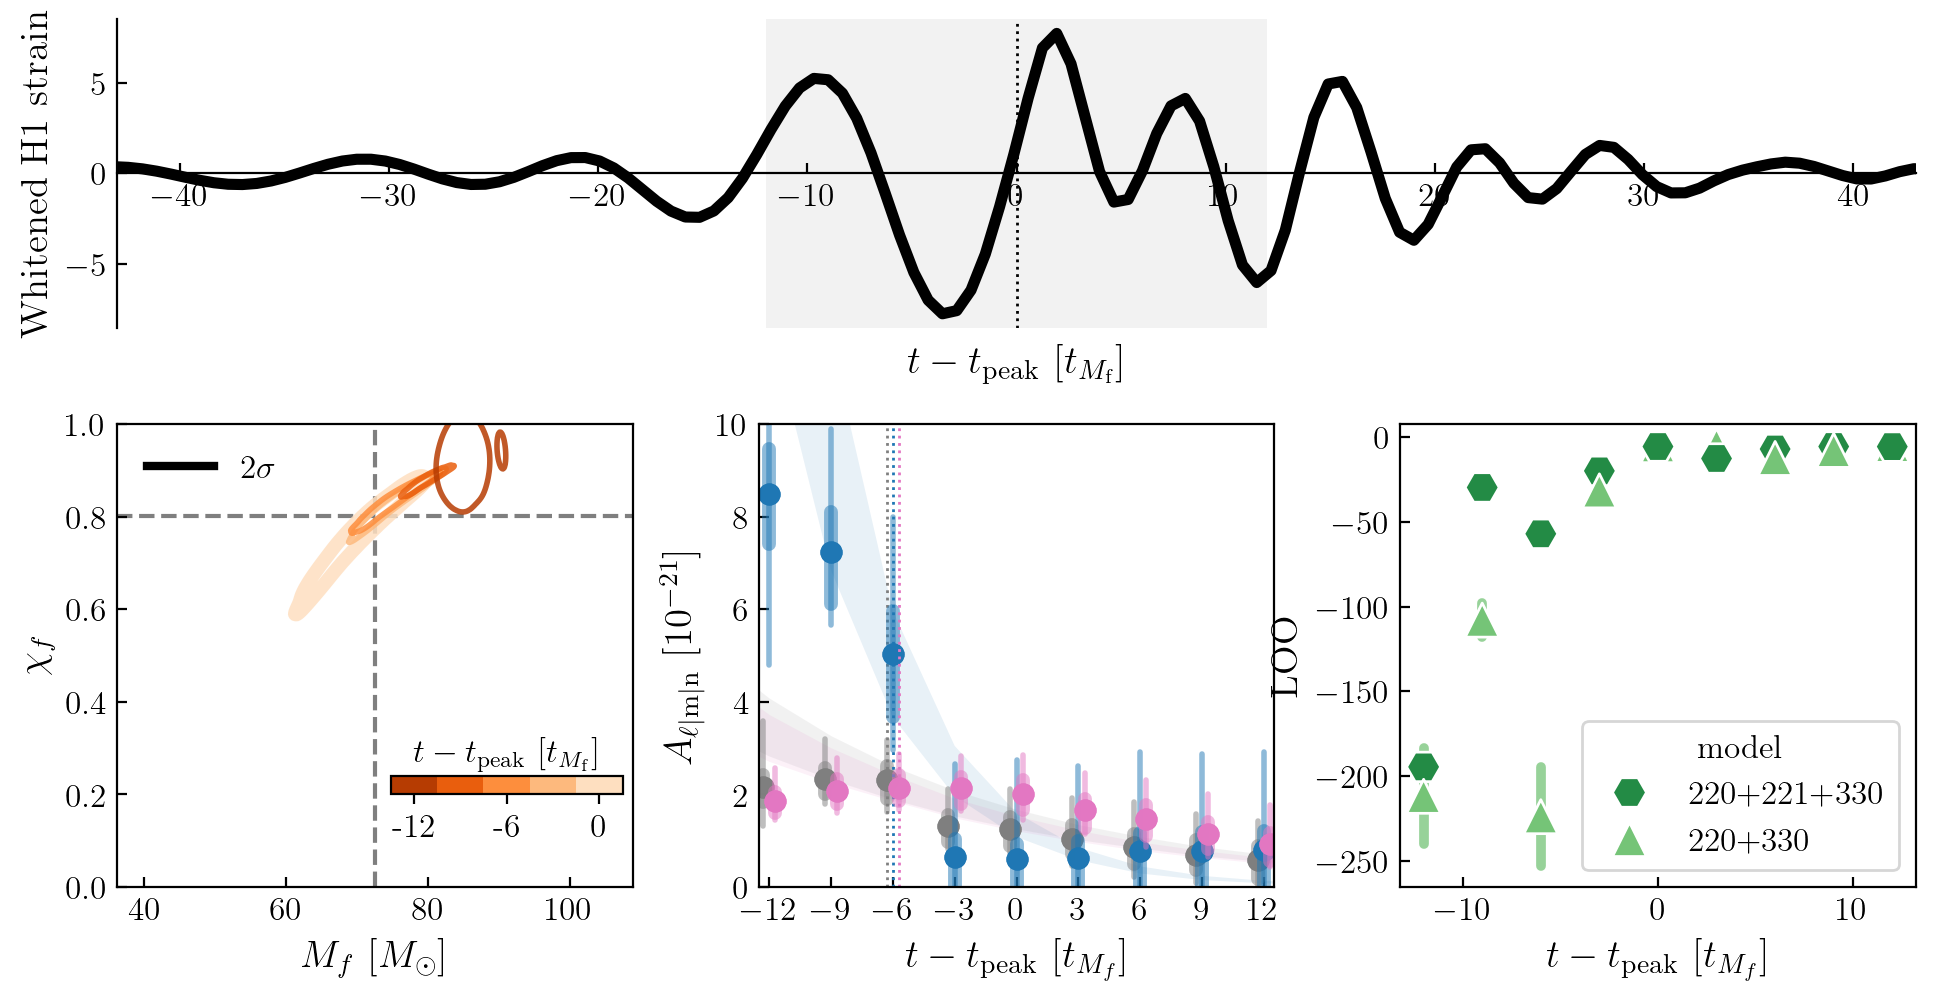

In [9]:
main('DS/220+330', ['220', '221', '330'], a_idx=[0, 1, 2], fcut='<500', tref=-6, comp_model='220+330', sub_hi=0, save=False)

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/DS/220+330/winj_ppSNR20_dfpre-0.5_dtaupre0.pkl...
Plotting m-chi...
Plotting amps...


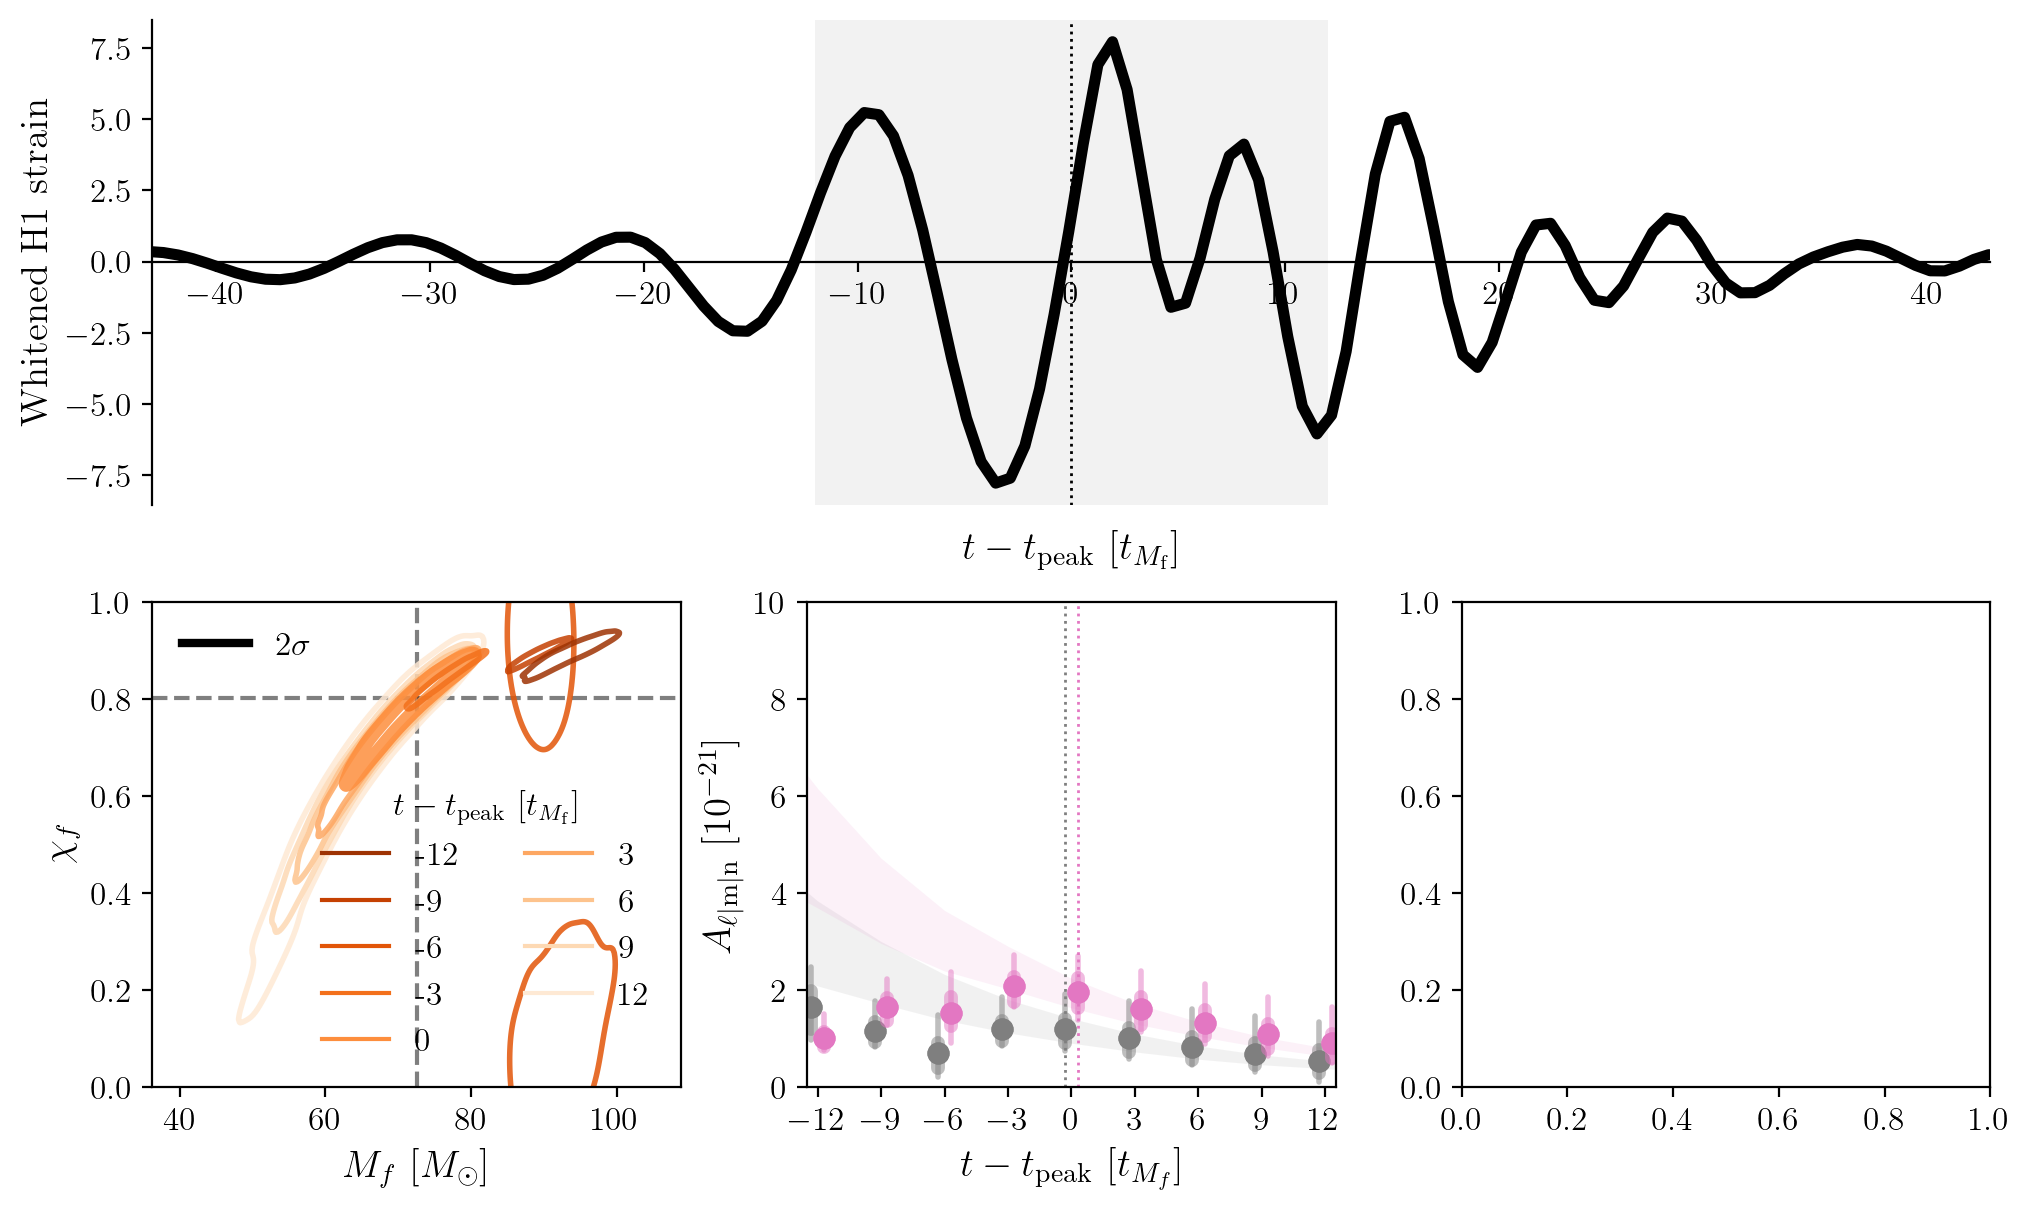

In [22]:
main('DS/220+330', ['220','330'], a_idx=[0, 1], fcut='<500', comp=False, tref=0)

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot330/winj_ppSNR20_mtot330_inclined.pkl...
Plotting m-chi...
Plotting amps...
Plotting LOOs...
Adding 220+330 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached LOO results from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot330/comp/loo_comp_dict_ppSNR20_mtot330_inclined.pkl...


/tmp/ipykernel_24497/452561921.py:230: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(comp_df, x='$t - t_{\\mathrm{peak}}$ [$t_{M_f}$]', y='elpd_loo', hue='model', style='model',


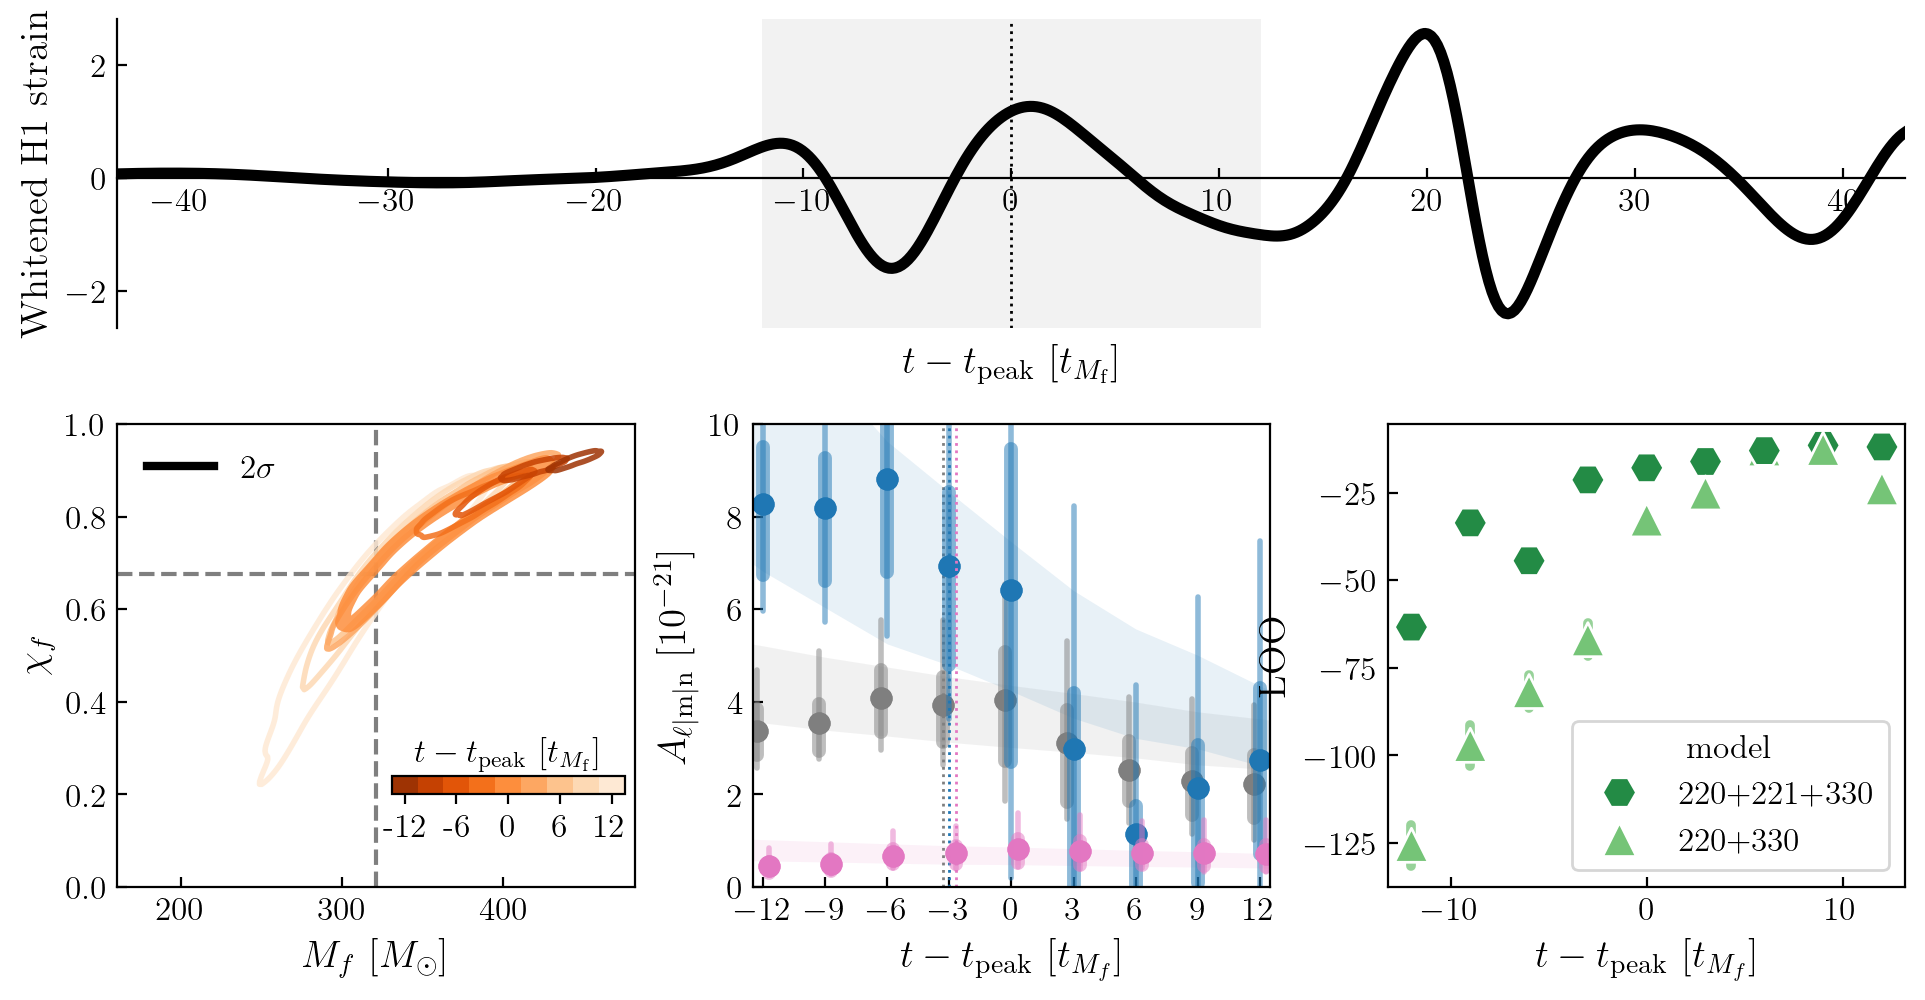

In [21]:
main('SXS_BBH_1156/mtot330', ['220', '221', '330'], a_idx=[0, 1, 2], fcut='>60', tref=-3)

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot72/winj_ppSNR20_mtot72_inclined.pkl...
Plotting m-chi...
Plotting amps...
Plotting LOOs...
Adding 220+330 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached LOO results from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot72/comp/loo_comp_dict_ppSNR20_mtot72_inclined.pkl...


/tmp/ipykernel_24497/452561921.py:230: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(comp_df, x='$t - t_{\\mathrm{peak}}$ [$t_{M_f}$]', y='elpd_loo', hue='model', style='model',


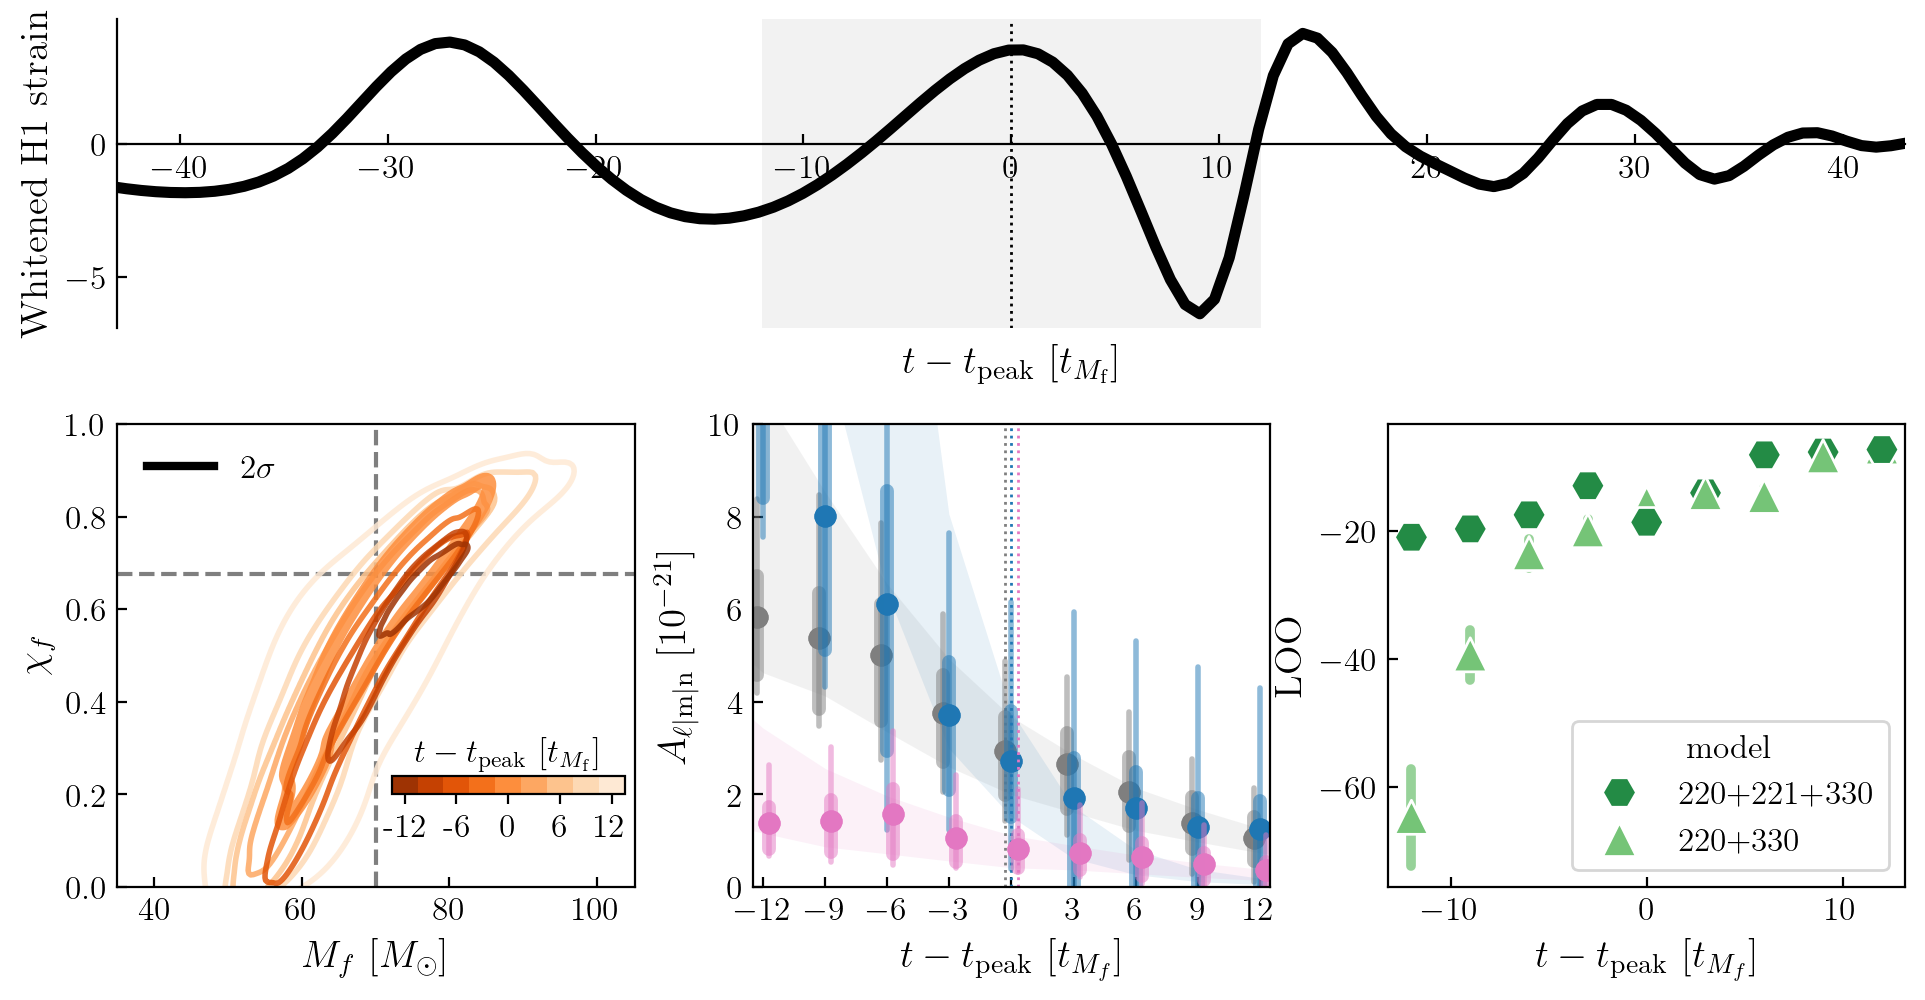

In [22]:
main('SXS_BBH_1156/mtot72', ['220', '221', '330'], a_idx=[0, 1, 2], fcut='>300')

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot72/winj_ppSNR20_mtot72_inclined.pkl...
Plotting m-chi...
Plotting amps...
Plotting LOOs...
Adding 220+221+330 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached LOO results from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot72/comp/loo_comp_dict_ppSNR20_mtot72_inclined.pkl...


/tmp/ipykernel_1842027/1650685399.py:213: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(comp_df, x='$t - t_{\\mathrm{peak}}$ [$t_{M_f}$]', y='elpd_loo', hue='model', style='model',


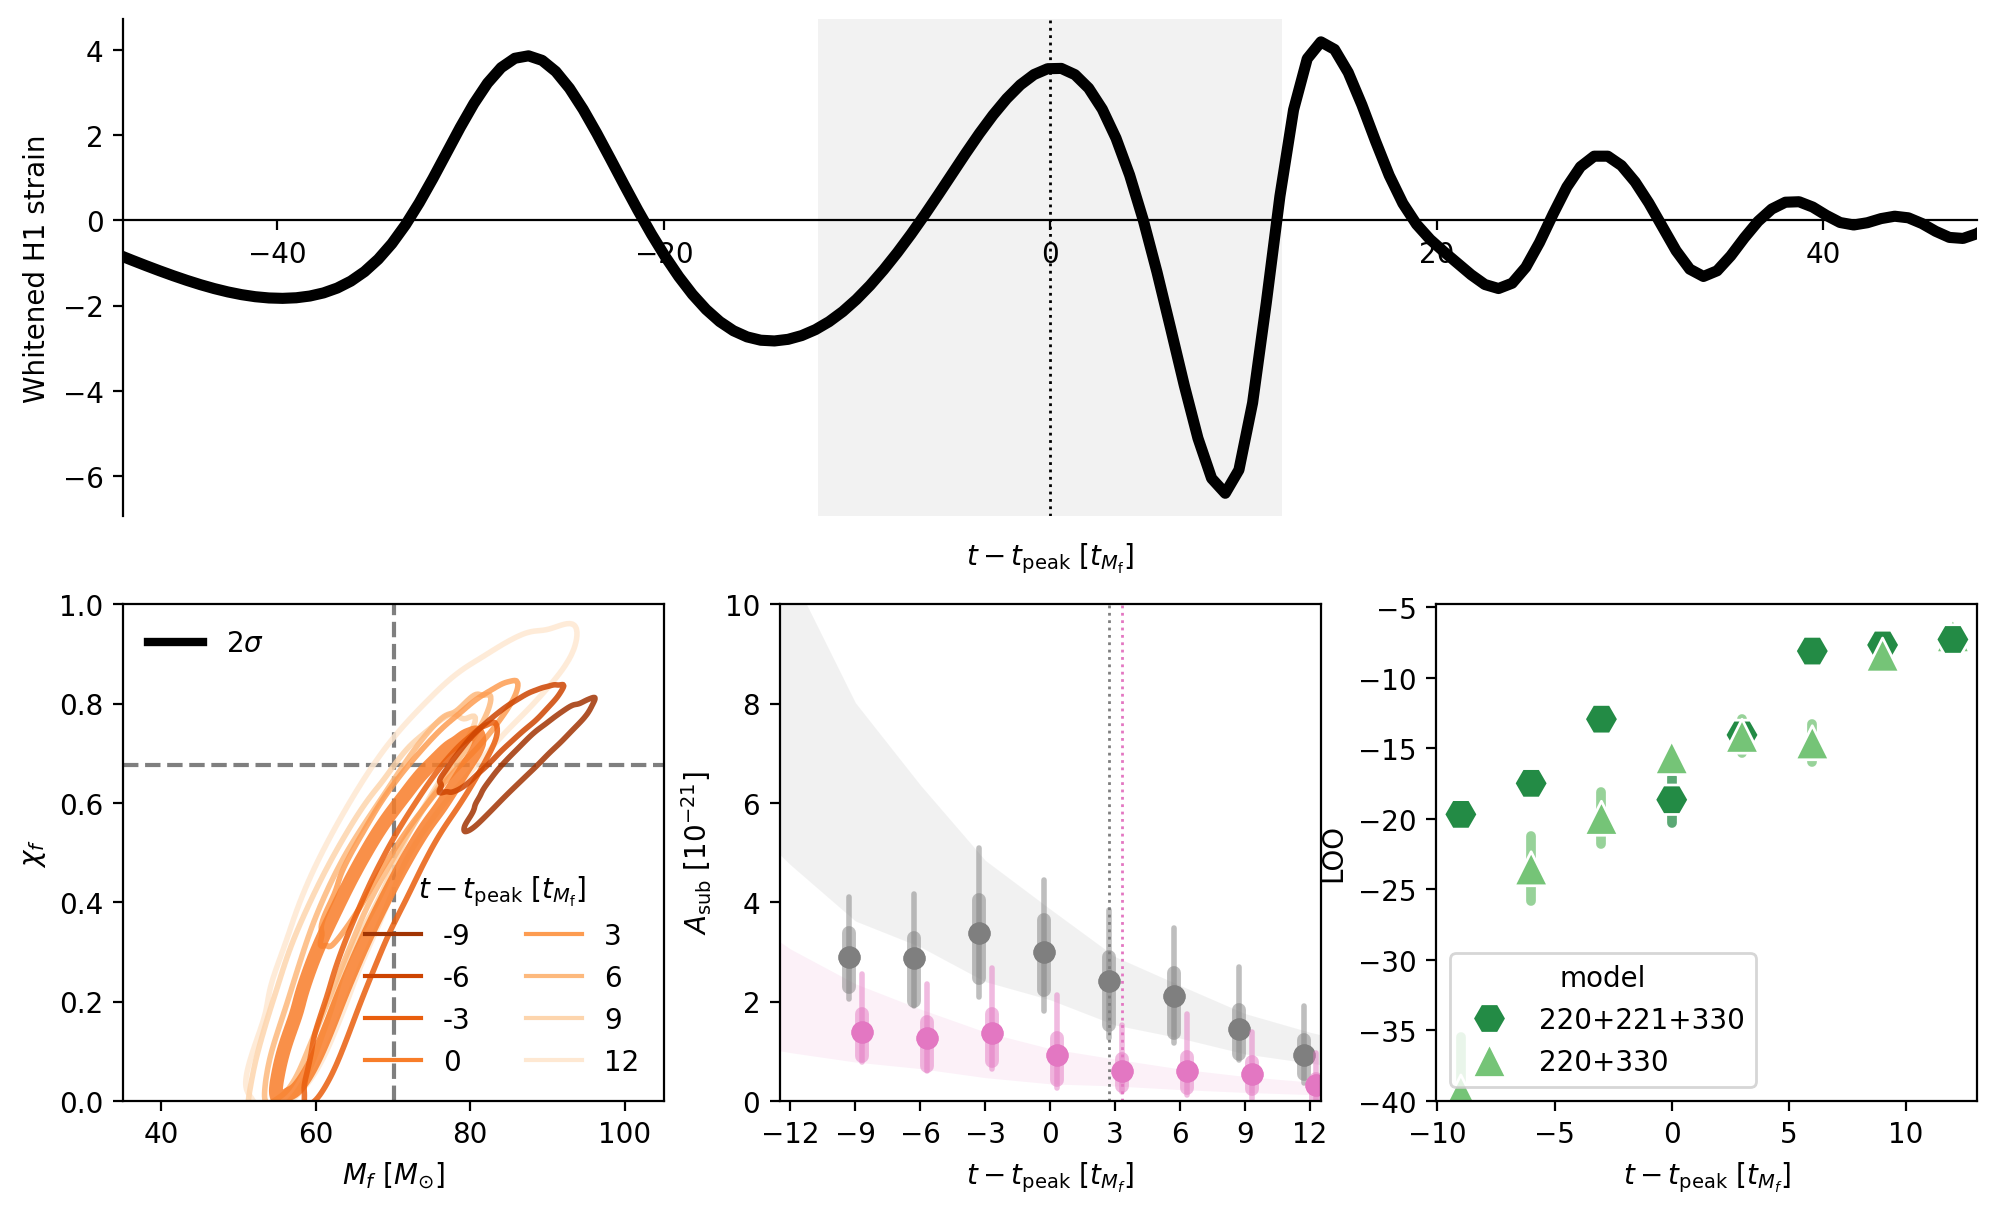

In [28]:
main('SXS_BBH_1156/mtot72', ['220', '330'], a_idx=[0, 1], fcut='>300', tref=3)

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot330/winj_ppSNR20_mtot330_inclined.pkl...
Plotting m-chi...
Plotting amps...
Plotting LOOs...
Adding 220+221+330 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached LOO results from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot330/comp/loo_comp_dict_ppSNR20_mtot330_inclined.pkl...


/tmp/ipykernel_1842027/1650685399.py:213: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(comp_df, x='$t - t_{\\mathrm{peak}}$ [$t_{M_f}$]', y='elpd_loo', hue='model', style='model',


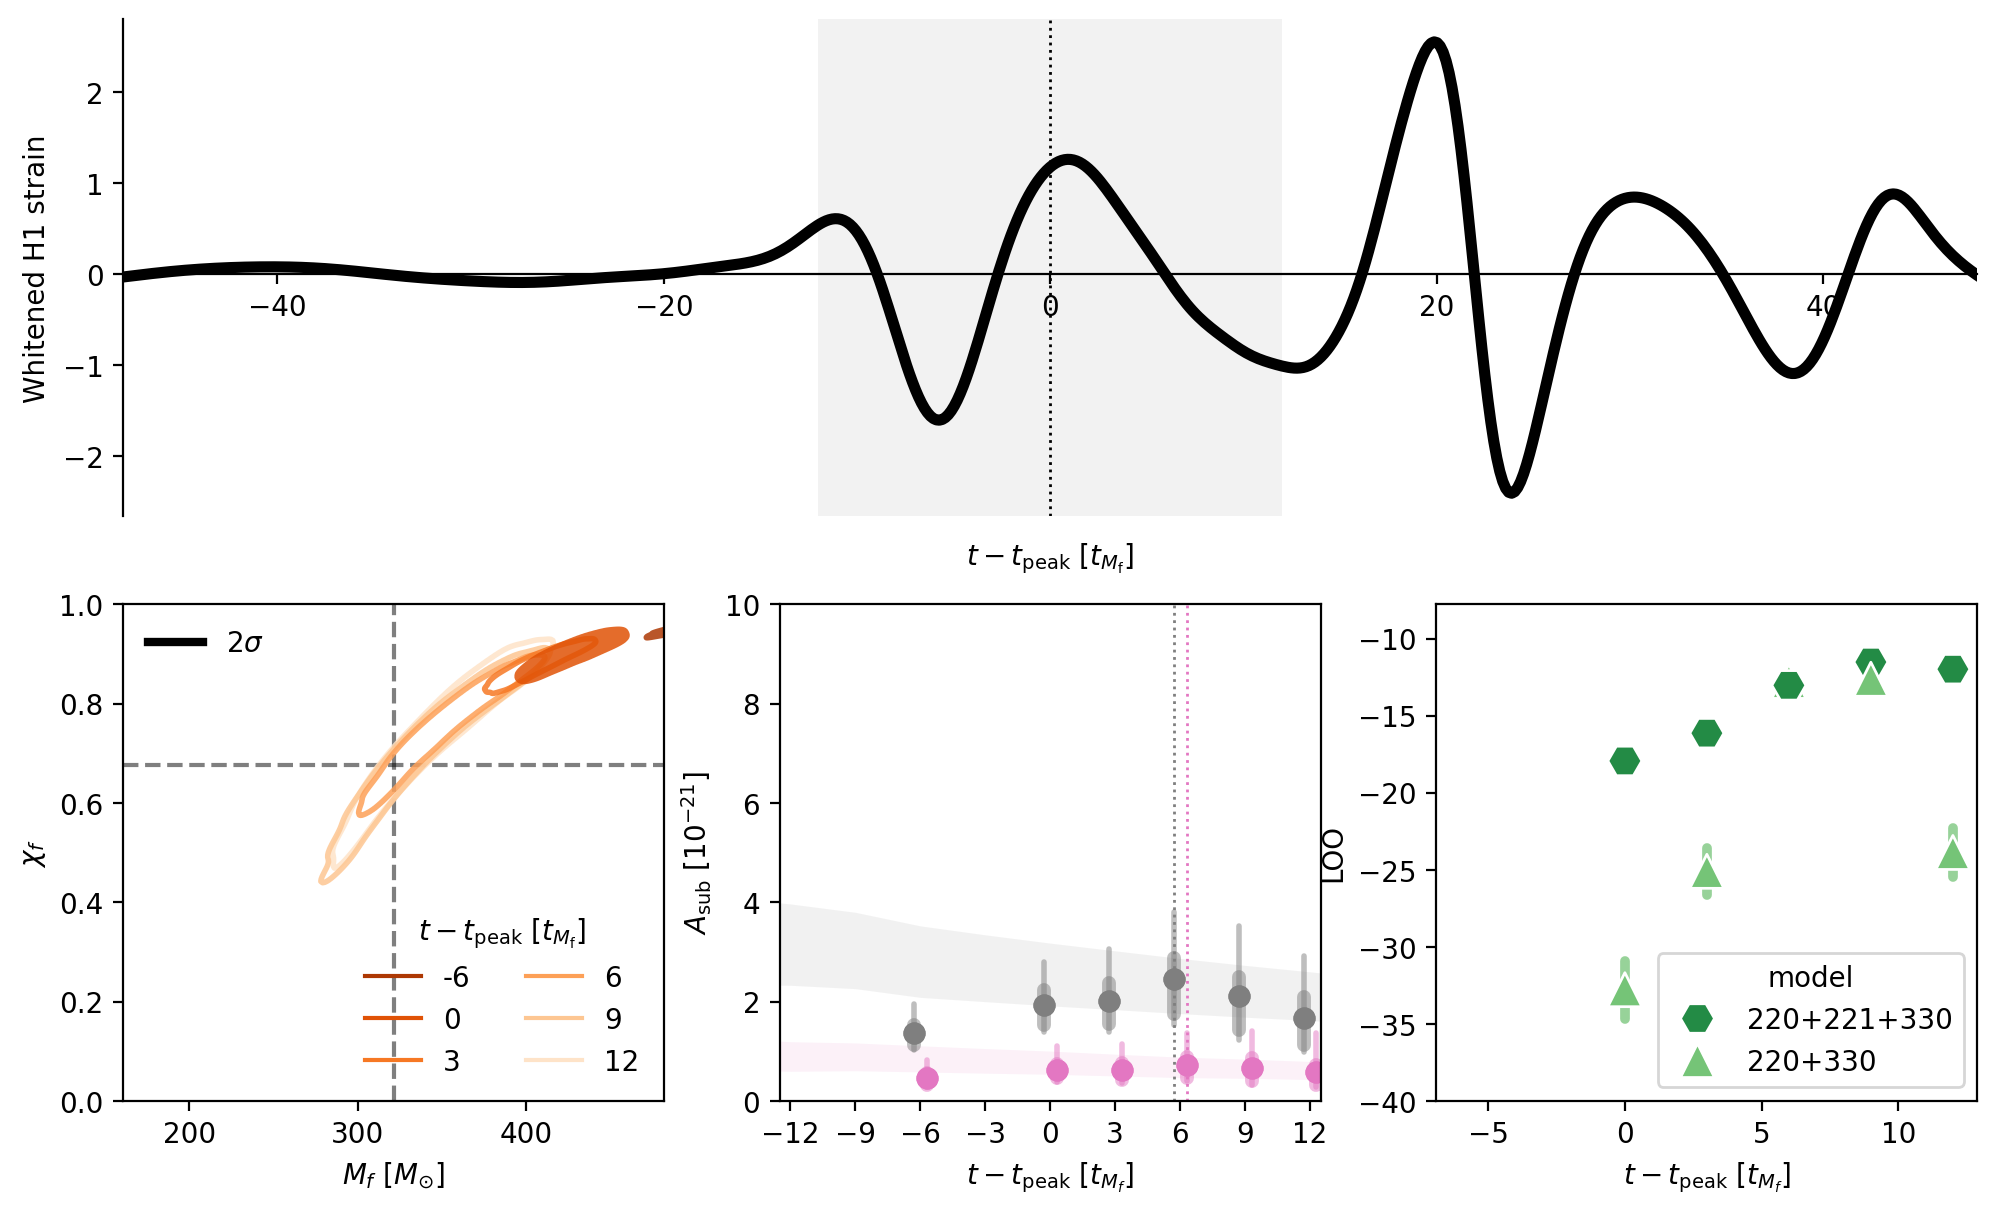

In [30]:
main('SXS_BBH_1156/mtot330', ['220', '330'], a_idx=[0, 1], fcut='>60', tref=6)

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1155/mtot72/winj_ppSNR20_mtot72_inclined.pkl...
Plotting m-chi...


UnboundLocalError: cannot access local variable 'df_sub' where it is not associated with a value

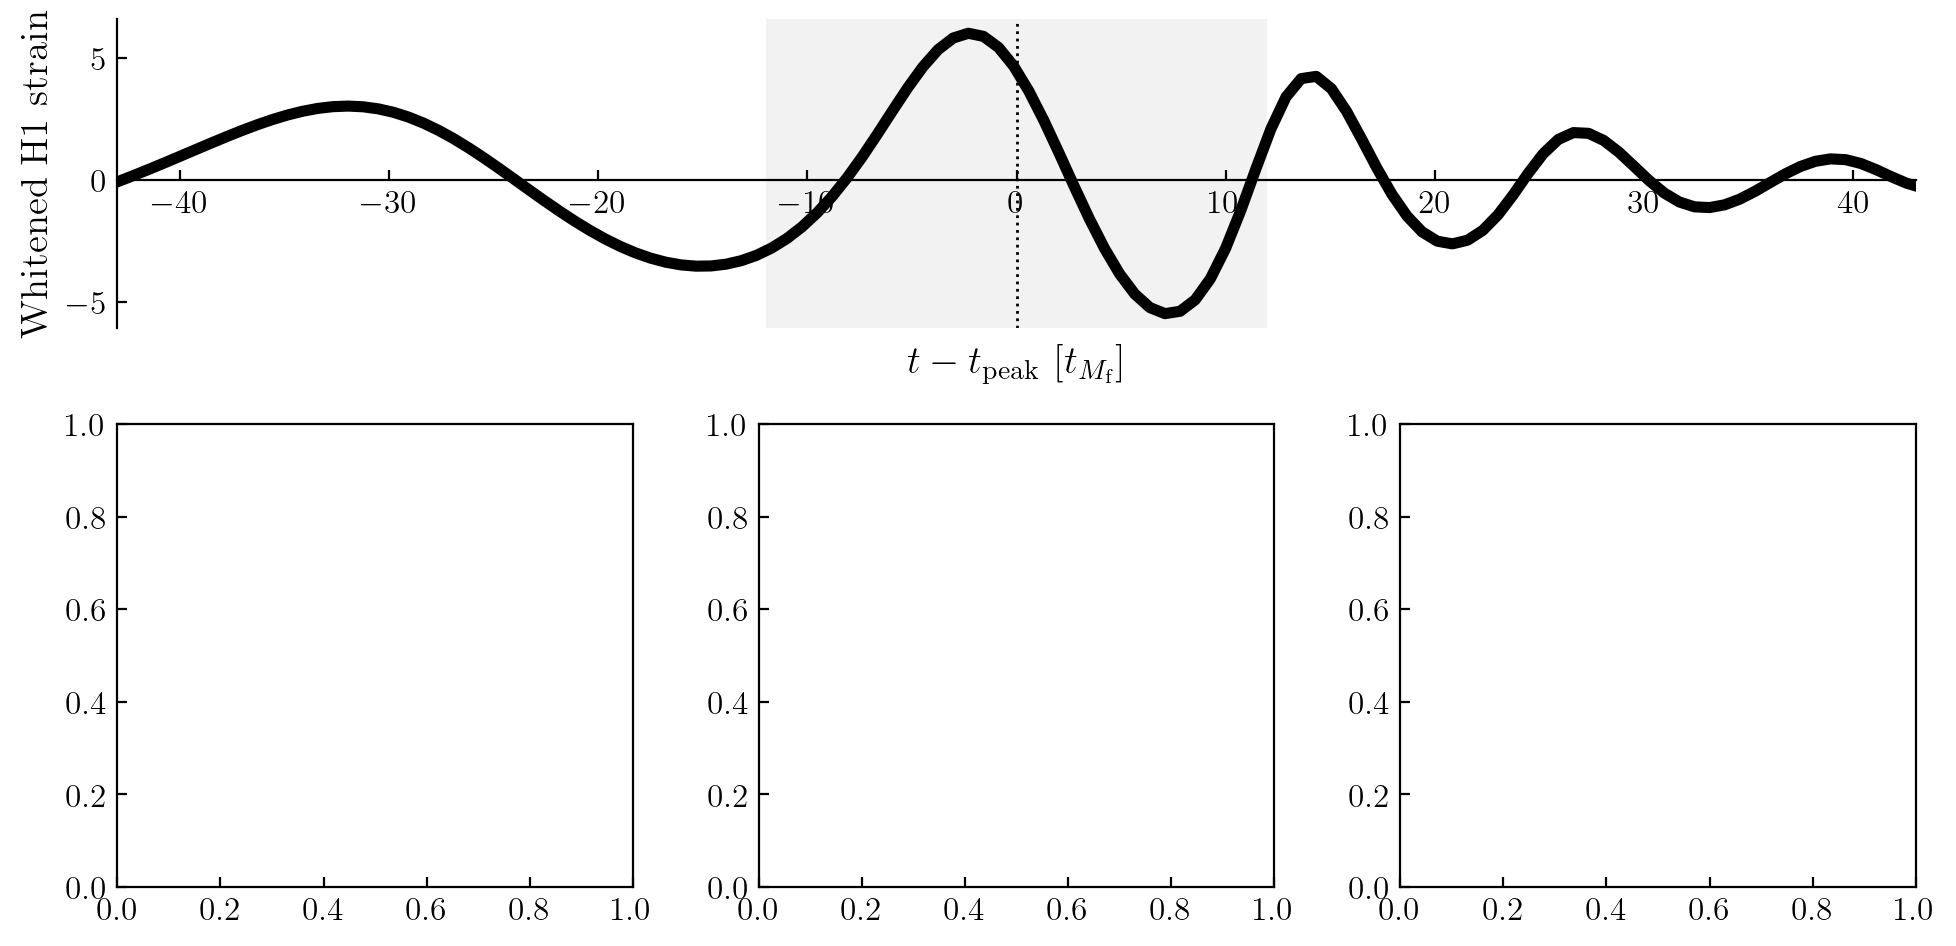

In [54]:
fig, axs = main('SXS_BBH_1155/mtot72', ['220', '221'], a_idx=[1], comp_model='220+221+222')

In [8]:
def main_combo(path: str, model: list, tref: int = 0, sub_lo: int = None, sub_hi: int = None, a_idx: list = None, comp: bool = True, cache: bool = True, fcut: str = None, gcut: str = None, comp_model: list = None, save: bool = True, figaxs: tuple = None, cbar_kws: dict = None, **kws):

    # parser = argparse.ArgumentParser()

    # parser.add_argument('--path', type=str, required=True, help="Path to subdir for injection type, e.g. 'DS/220' or 'SXS_BBH_1155/mtot330'")

    # parser.add_argument('--model', nargs='+', required=True, type=str, help='Modes in QNM model whose results to plot, e.g. --model 220 210')

    # parser.add_argument('--tref', required=False, default=0, type=int, help='Analysis time from which to project amplitude posterior, e.g. --tref -3. Default is --tref 0.')

    # parser.add_argument('--no-comp', action='store_false', dest='comp', default=True, help='Do not generate LOO model comparison plot.')

    # parser.add_argument('--no-cache', action='store_false', dest='cache', default=True, help='No LOO cache, compute from scratch.')

    # parser.add_argument('--fcut', type=str, default=None)

    # parser.add_argument('--gcut', type=str, default=None)

    # args = parser.parse_args()

    modes = model
    combo = '+'.join(modes)
    # fcut = args.fcut
    # gcut = args.gcut
    ifo = 'H1'

    if 'DS' in path:
        morph = 'dfpre-0.5_dtaupre0'
    else:
        morph = f'{path.split("/")[-1]}_inclined'
    inj_path = glob.glob(str(dirs.datdir / 'injections' / path / f'*ppSNR20_{morph}_{ifo}.hdf5'))
    inj = pd.read_hdf(inj_path[0], key=ifo)

    if 'DS' in path:
        injtype = 'DS_GW250114Kerr'
    else:
        injtype = f'{path.split("/")[0]}'

    # single_ds = rd.Result.from_netcdf(str(dirs.resdir / path / f'220_{injtype}_fmin10Hz_ppSNR20_{morph}' / 'engine' / f'{inj_ds.t0:.6f}' / 'result.nc'))

    suffix = kws.pop("suffix", "")
    if isinstance(suffix, list):
        suffix, extra_suffix = suffix
    else:
        extra_suffix = suffix
    run = dirs.resdir / path / f'{combo}_{injtype}_fmin10Hz_ppSNR20_{morph}{suffix}'
    config_ref = run / 'config.ini'
    remnant = Remnant(str(config_ref))
    mref = remnant.m
    cref = remnant.chi

    coll = rd.ResultCollection.from_netcdf(str(run / 'engine' / '*' / 'result.nc'))
    coll.reindex_by_t0(reference_time=inj_ds.t0, reference_mass=mref, decimals=0)
    df = coll.get_parameter_dataframe(ndraw=4000, progress=True, prng=13)
    runs = df['run'].unique()
    
    if fcut is not None:
        sub_mode = combo.split('+')[-1]
        if '<' in fcut:
            df = df[df[f'f_{sub_mode}'] < float(fcut[1:])]
        else:
            df = df[df[f'f_{sub_mode}'] > float(fcut[1:])]
    if gcut is not None:
        sub_mode = combo.split('+')[-1]
        if '<' in gcut:
            df = df[df[f'g_{sub_mode}'] < float(gcut[1:])]
        else:
            df = df[df[f'g_{sub_mode}'] > float(gcut[1:])]
    # dfs[combo] = df
    df_sub = df
    if sub_lo is not None and sub_hi is not None:
        df_sub = df[(df['run'] >= sub_lo) & (df['run'] <= sub_hi)]
    elif sub_lo is not None:
        df_sub = df[df['run'] >= sub_lo]
        # idx_lo = np.argwhere(runs == sub_lo)[0]
    elif sub_hi is not None:
        df_sub = df[df['run'] <= sub_hi]
        # idx_hi = np.argwhere(runs == sub_hi)[0]

    psd_path = coll[0].config['acf']['path'][ifo]
    fit = rd.Fit()
    fit.load_data({ifo: inj_path[0]})
    fit.set_target(inj_ds.t0, inj_ds.ra, inj_ds.dec, inj_ds.psi, duration=0.5)
    TM = rd.qnms.T_MSUN * mref

    cachewinjdir = dirs.datdir / 'injections' / path
    if not cachewinjdir.exists():
        cachewinjdir.mkdir(parents=True)
    cachewinj_path = cachewinjdir / f'winj_ppSNR20_{morph}.pkl'

    if cachewinj_path.exists():
        print(f'Loading cached whitened injection from {cachewinj_path}...')
        with open(cachewinj_path, 'rb') as f:
            winj = pickle.load(f)
    else:
        print('No cached whitened injection, whitening now...')

        fit.load_acfs(from_psd=True, path={ifo: psd_path})
        winj = fit.whiten({ifo: inj})

        with open(cachewinj_path, 'wb') as f:
            pickle.dump(winj, f)
        print(f'Saved whitened injection to {cachewinj_path}')

    if figaxs is not None:
        fig, (ax_top, ax1, ax2, ax3) = figaxs
    else:
        fig = plt.figure(figsize=kws.pop('figsize', (10, 5)))
        gs = gridspec.GridSpec(2, 3, figure=fig, height_ratios=[1, 1.5])  
        # fig.subplots_adjust(wspace=0.5)

        ax_top = fig.add_subplot(gs[0, :])
        ax1 = fig.add_subplot(gs[1, 0])
        ax2 = fig.add_subplot(gs[1, 1])
        ax3 = fig.add_subplot(gs[1, 2])

        pos = ax3.get_position()
        ax3.set_position([
            pos.x0 + 0.05,
            pos.y0,
            pos.width * 0.85,
            pos.height
        ])

        plt.tight_layout()

        for ax in fig.axes:
            ax.tick_params(axis='both', which='both', direction='in')

    # fig.align_ylabels()

    ### plotting injection
    times = (inj.index.values - fit.start_times[ifo]) / TM
    if kws.pop('plot_inj', True):
        l, = ax_top.plot(times, winj[ifo], color='k', lw=4)
        # ax_top.plot(times[(times >= 0) & (times <= 0.5/TM)], single_ds.whitened_data[0], lw=5, color='gray', alpha=0.5)
        # ax_top.plot(times[(times >= 0) & (times <= 0.5/TM)], np.quantile(single_ds.whitened_templates[0,:,:], q=0.5, axis=-1), lw=2.5, color='red', alpha=0.5, ls='--')
        ax_top.axvline(0, color='k', ls=':', lw=1)
        # ax_top.axhline(0, color='red', ls=':', lw=1)
        ax_top.axvspan(-12, 12, color='gray', alpha=0.1, lw=0)
        ax_top.set_xlim(-43, 43)
        ax_top.set_xlabel('$t_> = t - t_{\mathrm{peak}}$ [$t_{M_{\mathrm{f}}}$]')
        ax_top.set_ylabel('Whitened H1 strain')

        ax_top.xaxis.set_label_coords(0.5, -0.05, transform=ax_top.transAxes)
        l.axes.spines['bottom'].set_position(('data', 0))
        l.axes.spines['top'].set_visible(False)
        l.axes.spines['right'].set_visible(False)
        # axis (spine at y=0, ticks, tick labels) above the strain curve; tick labels get a white
        # outline so the curve does not run through them
        import matplotlib.patheffects as pe
        ax_top.set_axisbelow(False)
        for tk in ax_top.xaxis.get_major_ticks():
            tk.label1.set_path_effects([pe.withStroke(linewidth=3, foreground='white')])

    modecol_map = {'221': 'blue',
                '210': 'purple',
                '330': 'orange',
                '222': 'red',
                '220': 'gray',
                '320': 'pink',
                '440': 'green'}

    model_color = kws.pop('model_color', modecol_map[modes[a_idx[0]]])
    custom_cmap = LinearSegmentedColormap.from_list(
        'custom',
        ['black', f'tab:{model_color}', 'white'],
        N=256
    )
    # 'cmap_span': 'all' (default) samples the colormap over all start times and keeps the plotted
    # subset (consistent colors across sub-ranges); 'subset' spreads the full color range over just
    # the plotted start times (more contrast when only a few are shown), between 'cmap_lims'
    # (default (0.2, 0.75): dark to light, stopping short of white so contours stay visible)
    keep = np.ones(len(runs), dtype=bool)
    if sub_lo is not None:
        keep &= runs >= sub_lo
    if sub_hi is not None:
        keep &= runs <= sub_hi
    if kws.pop('cmap_span', 'all') == 'subset':
        palette = np.array(sns.color_palette(
            [custom_cmap(i) for i in np.linspace(*kws.pop('cmap_lims', (0.3, 0.75)), keep.sum())]
        ))
    else:
        palette = np.array(sns.color_palette(
            [custom_cmap(i) for i in np.linspace(0.25, 0.9, len(runs))]
        ))[keep]

    ### plotting m-chi
    print('Plotting m-chi...')
    print(df_sub['run'].unique())
    cbar_kws = dict(cbar_kws or {})
    plot_mfcf_man(df_sub, mref, cref, ax1, legend=False, palette=palette)
    # chi_f tick labels without trailing zeros (0, 0.2, ..., 1)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v:g}$'))

    # single shared start-time bar between the two rows (one strip per call)
    if kws.pop('legend', True):
        # (also resizes the figure height so the gap between rows just fits the bar)
        add_shared_tbar(fig, df_sub['run'].unique(), palette, ax_ref=ax_top, ax_col=ax1,
                        dt=np.min(np.diff(np.sort(runs))),
                        text=cbar_kws.pop('cbar_text', combo), text_color=f'tab:{model_color}', **cbar_kws)

    ### plotting amps
    print('Plotting amps...')

    if a_idx is not None:
        a_modes = [modes[i] for i in a_idx]
    else:
        a_modes = modes[-1]

    for m, a_mode in enumerate(a_modes):
        acol = model_color
        clevs = [0.95, 0.68]
        a_df = get_projection(df, a_mode, tref)

        shift = kws.pop('shift', np.linspace(-0.3, 0.3, len(a_modes))[m])
        a_scale = 1e-21
        plot_scan(df, a_mode, clevs, f'tab:{acol}', ax2, marker='o', shift=shift, a_scale=a_scale)
        plot_projection(a_df, [min(clevs)], ax2, color=f'tab:{acol}', a_scale=a_scale)
        ax2.axvline(tref+shift, ls=':', lw=1, color=f'tab:{acol}')

        ax2.set_xlabel('$t_>$ [$t_{M_{\\mathrm{f}}}$]')
        ax2.set_xticks(np.arange(-12, 15, 3))
        ax2.set_xlim(-12.5, kws.pop('a_xlim', 12.5))

        ax2.set_ylabel(f'$A_{{\mathrm{{\ell |m| n}}}}^{{\mathbf{{bold}}}}$ [$10^{{{int(np.log10(a_scale))}}}$]')
        a_max = np.quantile(df[df['run'] == tref][f"a_{a_mode}"].values, 0.55) * 2
        # ax2.set_ylim(0, np.ceil(a_max / a_scale))
        ax2.set_ylim(0, kws.pop('a_ylim', 20))
        ax2.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

        # legend label: full QNM model, with the mode whose amplitude is plotted in boldface
        bold = (lambda s: r'\textbf{%s}' % s) if plt.rcParams['text.usetex'] else (lambda s: r'$\mathbf{%s}$' % s)
        a_label = '+'.join(bold(md) if md == a_mode else md for md in modes)
        # one legend shared by all calls on this ax2: entries accumulate, so they stay aligned.
        # Title and location come from the first call ('leg_title', 'leg_loc').
        if not hasattr(ax2, '_amp_leg'):
            ax2._amp_leg = dict(handles=[], labels=[], title=kws.pop('leg_title', 'Model'),
                                loc=kws.pop('leg_loc', 'upper right'), artist=None)
        for k in ('leg_title', 'leg_loc', 'leg_y'):  # ignored on later calls
            kws.pop(k, None)
        amp_leg = ax2._amp_leg
        amp_leg['handles'].append(plt.Line2D([], [], color=f'tab:{acol}', lw=3))
        amp_leg['labels'].append(a_label)
        if amp_leg['artist'] is not None:
            amp_leg['artist'].remove()
        amp_leg['artist'] = ax2.legend(amp_leg['handles'], amp_leg['labels'], frameon=False, fontsize=12,
                                       loc=amp_leg['loc'], title=amp_leg['title'], title_fontsize=12)
        ax2.add_artist(amp_leg['artist'])

    ### plotting loos
    if comp:
        print('Plotting LOOs...')

        # Loading results from all models
        loo_colls = {combo: coll}
        loo_fcut = {combo: fcut}
        loo_gcut = {combo: gcut}


        if comp_model is not None:
            extra_combos = [str(dirs.resdir / path / f'{cm}_{injtype}_fmin10Hz_ppSNR20_{morph}{extra_suffix}') for cm in comp_model]    
        else:
            extra_combos = glob.glob(str(dirs.resdir / path / f'*_{injtype}_fmin10Hz_ppSNR20_{morph}{extra_suffix}'))

        extra_fcut = kws.pop('extra_fcut', [None]*len(extra_combos))
        extra_gcut = kws.pop('extra_gcut', [None]*len(extra_combos))
        for i, run_path in enumerate(extra_combos):
            extra_combo = run_path.split('/')[-1].split('_')[0]
            if extra_combo not in loo_colls.keys():
                print(f'Adding {extra_combo} to model comparison...')
                coll = rd.ResultCollection.from_netcdf(f'{run_path}/engine/*/result.nc')
                coll.reindex_by_t0(reference_time=inj_ds.t0, reference_mass=mref, decimals=0)
                loo_colls[extra_combo] = coll
                loo_fcut[extra_combo] = extra_fcut[i]
                loo_gcut[extra_combo] = extra_gcut[i]

        cachedir = dirs.datdir / 'injections' / path / 'comp'
        if not cachedir.exists():
            cachedir.mkdir(parents=True)
        cache_path = cachedir / f'loo_comp_dict_ppSNR20_{morph}.pkl'

        if cache_path.exists() & cache:
            print(f'Loading cached LOO results from {cache_path}...')
            with open(cache_path, 'rb') as f:
                loo_results = pickle.load(f)

        else:
            print('No cached LOO results, computing now...')

            # Parallelizing
            max_workers = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count()))

            tasks = [(combo, s, r.idx[s], loo_fcut[combo], loo_gcut[combo]) for combo, r in loo_colls.items() for s in df['run'].unique()]
            loo_results = {}   # (key, value) = ((combo, s), ELPDData)
            with ProcessPoolExecutor(max_workers=max_workers) as executor:
                futures = {executor.submit(_compute_loo, t): t for t in tasks}
                for fut in as_completed(futures):
                    cb, s, loo_res = fut.result()
                    loo_results[(cb, s)] = loo_res

            with open(cache_path, 'wb') as f:
                pickle.dump(loo_results, f)
            print(f'Saved LOO results to {cache_path}')

        starts = df['run'].unique()
        loo_dict = pd.DataFrame({combo: [loo_results[(combo, s)].elpd_loo for s in starts] for combo in loo_colls},
                                index=np.array(starts))

        tcol = '$t_>$ [$t_{M_{\\mathrm{f}}}$]'
        model_dfs = []
        for s in loo_dict.index:
            model_df = az.compare({combo: loo_results[(combo, s)] for combo in loo_colls}, ic='loo')
            model_df[tcol] = s
            model_dfs.append(model_df)

        comp_df = pd.concat(model_dfs, ignore_index=False)
        comp_df['model'] = comp_df.index

        palette = kws.pop('palette', sns.color_palette('Greens_r', n_colors=len(comp_df['model'].unique())+1))
        markers = ['H', '^', 'X', '*', 'P', '>']
        marker_map = dict(zip(comp_df['model'].unique(), markers))
        # one point at a time, in comp_df row order (same layering as sns.scatterplot), no legend;
        # per-marker area scale so all markers look about the same size ('*' is drawn small)
        marker_scale = {'*': 2.3}
        models = list(comp_df['model'].unique())
        for _, r in comp_df.iterrows():
            mk = marker_map[r['model']]
            ms = 150*marker_scale.get(mk, 1)
            ax3.scatter(r[tcol], r['elpd_loo'], marker=mk, s=ms, color=palette[models.index(r['model'])],
                        edgecolors='w', linewidths=0.08*np.sqrt(ms))
        ax3.set_xlabel(tcol)
        for i in range(len(comp_df)):
            if comp_df.iloc[i]['rank'] != 0:
                _, caps, bars = ax3.errorbar(x=comp_df.iloc[i][tcol], y=comp_df.iloc[i]['elpd_loo'], yerr=comp_df.iloc[i]['se'], lw=3.5, c=palette[list(comp_df.index.unique()).index(comp_df.index[i])], capsize=None, alpha=0.75, zorder=-1)
                for bar in bars:
                    bar.set_capstyle('round')
        ax3.set_ylabel('LOO')
        # ax3.set_yscale('symlog', linthresh=1)
        # ax3.axhline(0, c='gray', ls='--', zorder=-1)
        # ax3.grid(alpha=0.2)
        # ax3.set_yticks(np.arange(0, 10))
        if 'loo_ylim' in kws:
            ax3.set_ylim(kws['loo_ylim'])
        if 'loo_xlim' in kws:   # e.g. loo_xlim=(-12.5, 12.5), or (None, 6) to set one side only
            ax3.set_xlim(kws['loo_xlim'])

        # keep the LOO y-label clear of ax2: shift ax3's left edge right (right edge fixed) if needed
        renderer = fig.canvas.get_renderer()
        ax3.yaxis.get_tightbbox(renderer)   # updates the y-label position
        lab_x0 = ax3.yaxis.label.get_window_extent(renderer).x0
        ax2_x1 = ax2.get_window_extent(renderer).x1
        min_gap = 0.08*fig.dpi             # inches -> pixels
        if lab_x0 - ax2_x1 < min_gap:
            dx = (min_gap - (lab_x0 - ax2_x1))/fig.bbox.width
            p3 = ax3.get_position()
            ax3.set_position([p3.x0 + dx, p3.y0, p3.width - dx, p3.height])

    if save:
        if 'DS' in path:
            fig.savefig(str(dirs.figdir / 'paper' / f'inj{path.split("/")[-1]}_fit{combo}_unit.pdf'), bbox_inches='tight')
        else:
            fig.savefig(str(dirs.figdir / 'paper' / f'inj{path.replace("/", "_")}_fit{combo}_unit.pdf'), bbox_inches='tight')

    # plt.show()
    return fig, (ax_top, ax1, ax2, ax3)

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/DS/220/winj_ppSNR20_dfpre-0.5_dtaupre0.pkl...
Plotting m-chi...
[-9. -6. -3.]
Plotting amps...
Plotting LOOs...
Adding 220+210 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

Adding 220+330 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

... (8 outputs left out)

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/DS/220/winj_ppSNR20_dfpre-0.5_dtaupre0.pkl...
Plotting m-chi...
[-9. -6. -3.]
Plotting amps...


results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/DS/220/winj_ppSNR20_dfpre-0.5_dtaupre0.pkl...
Plotting m-chi...
[-9. -6. -3.]
Plotting amps...


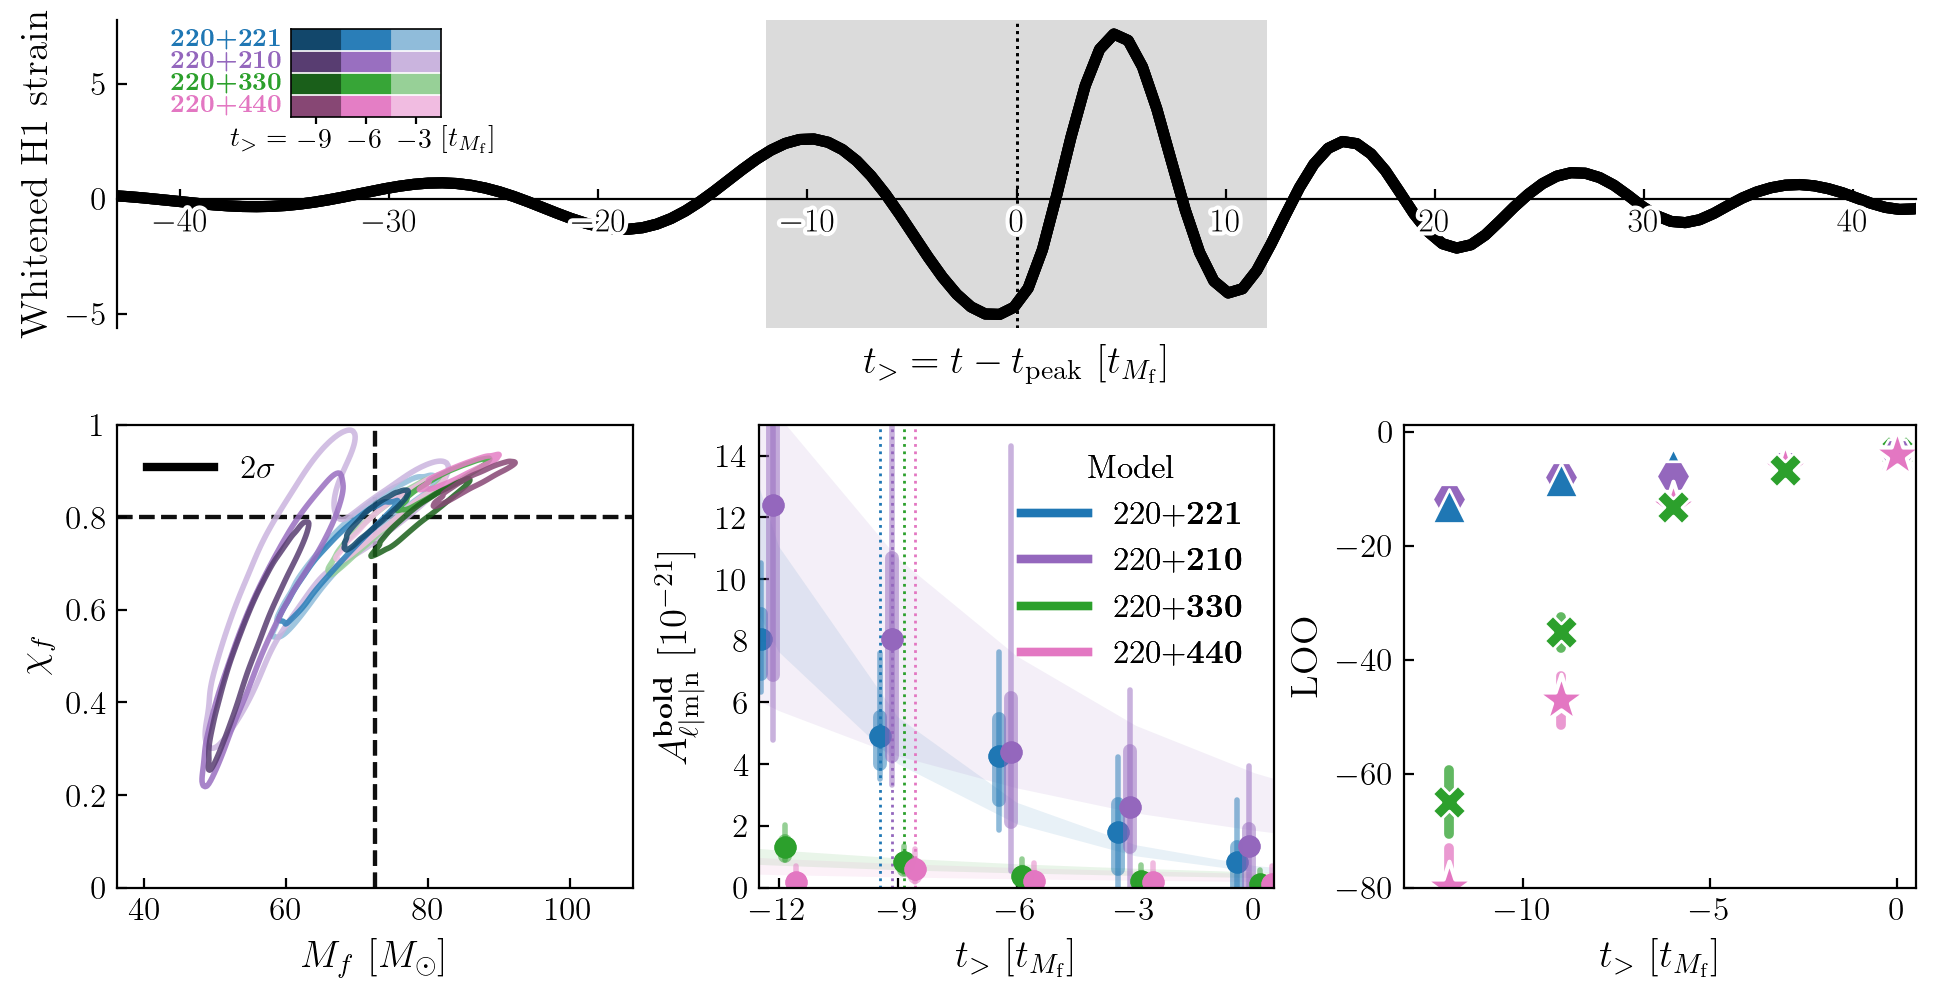

In [12]:
fig0, axs0 = main_combo('DS/220', ['220', '221'], sub_lo=-9, sub_hi=-3, a_idx=[1], tref=-9, comp_model=['220+210', '220+330', '220+440'], cbar_kws=dict(cbar_bottom=0.5, label=False), **dict(cmap_span='subset', shift=-0.45, model_color='blue', loo_ylim=-80, palette=['tab:purple', 'tab:blue', 'tab:green', 'tab:pink'], extra_fcut=[None, '>290', '>290'], loo_xlim=(None, 0.5)), save=False)

fig, axs = main_combo('DS/220', ['220', '210'], sub_lo=-9, sub_hi=-3, a_idx=[1], tref=-9, comp=False, figaxs=(fig0, axs0), cbar_kws=dict(cbar_label='', cbar_bottom=0.4, label=False), **dict(cmap_span='subset', shift=-0.15, leg_y=0.6, leg_title='', model_color='purple', loo_xlim=(None, 0.5)), save=False)
# fig1, axs1 = main_combo('DS/220', ['220', '210'], sub_lo=-9, sub_hi=-3, a_idx=[1], comp=False, tref=-6, figaxs=(fig, axs), cbar_kws=dict(cbar_bottom=0.35), **dict(shift=0.3, leg_y=0.6, leg_title='', model_color='purple'), save=False)

fig1, axs1 = main_combo('DS/220', ['220', '330'], fcut='>290', sub_lo=-9, sub_hi=-3, a_idx=[1], comp=False, tref=-9, figaxs=(fig, axs), cbar_kws=dict(cbar_label='', cbar_bottom=0.3, label=False), **dict(cmap_span='subset', shift=0.15, leg_y=0.5, leg_title='', model_color='green', loo_xlim=(None, 0.5)), save=False)

_, _ = main_combo('DS/220', ['220', '440'], fcut='>290', sub_lo=-9, sub_hi=-3, a_idx=[1], comp=False, tref=-9, figaxs=(fig1, axs1), cbar_kws=dict(cbar_label='', cbar_bottom=0.2), **dict(cmap_span='subset', shift=0.45, leg_y=0.4, leg_title='', model_color='pink', a_xlim=0.5, a_ylim=15, plot_inj=False, loo_xlim=(None, 0.5)))

fig.show()

In [8]:
run = 'SXS_BBH_1156/mtot72/linesub/220+221+330_SXS_BBH_1156_fmin10Hz_ppSNR20_mtot72_inclined'
coll = rd.ResultCollection.from_netcdf(f'{str(dirs.resdir / run)}/engine/*/result.nc')
coll.reindex_by_t0(reference_time=1126259462.423, reference_mass=coll[0].config['model']['m_min'] * 2, decimals=0)
TM = rd.qnms.T_MSUN * coll[0].config['model']['m_min'] * 2

start = -6
time_idx = coll.idx[start].constant_data.time_index.values
T = coll[0].config['target']['duration']
times_s = (T / len(time_idx)) * time_idx
times = start + times_s / TM

wmed = np.quantile(coll.idx[start].whitened_templates[0], 0.5, axis=-1)

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1155/mtot72/winj_ppSNR20_mtot72_inclined.pkl...
Plotting m-chi...
[-3.  0.  3.  6.  9. 12.]
Plotting amps...
Plotting LOOs...
Adding 220 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

Adding 220+221+222 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached LOO results from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1155/mtot72/comp/loo_comp_dict_ppSNR20_mtot72_inclined.pkl...


results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1155/mtot72/winj_ppSNR20_mtot72_inclined.pkl...
Plotting m-chi...
[-12.  -9.  -6.]
Plotting amps...


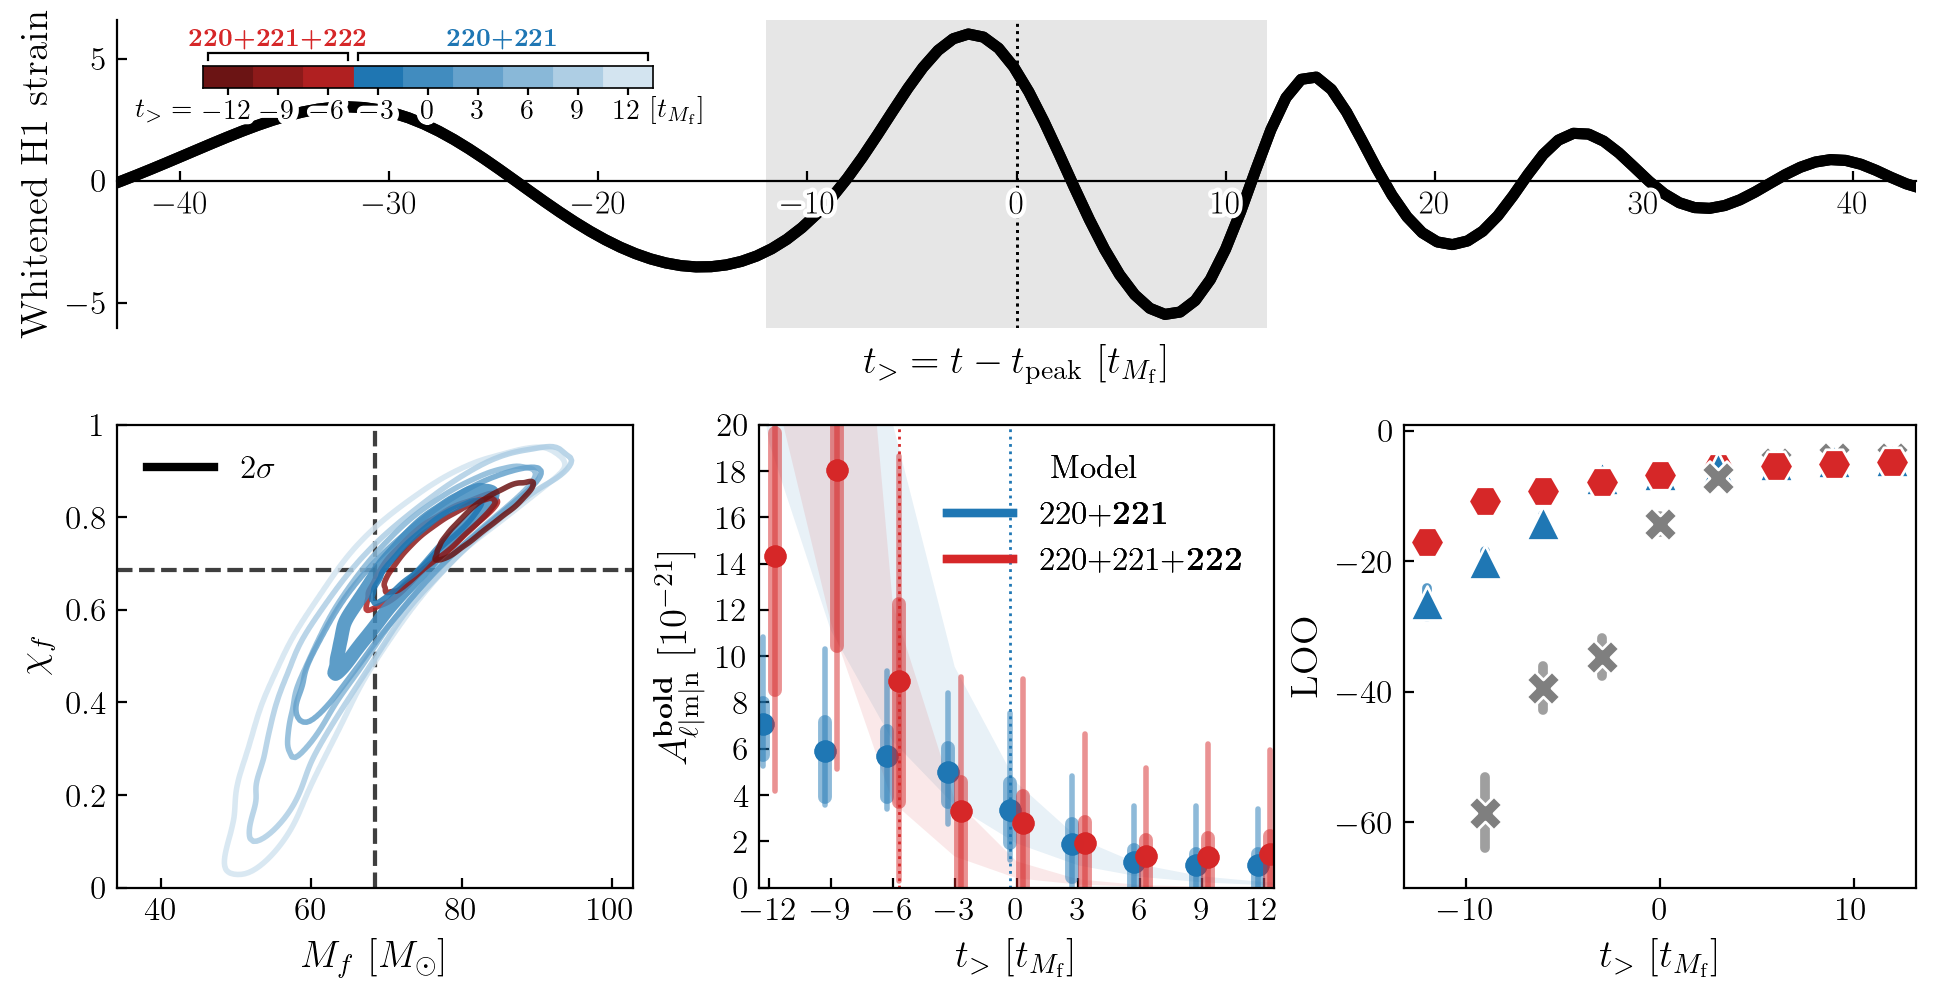

In [9]:
fig, axs = main_combo('SXS_BBH_1155/mtot72', ['220', '221'], sub_lo=-3, a_idx=[1], comp_model=['220', '220+221+222'], cbar_kws=dict(cbar_label=''), **dict(shift=-0.3, palette=['tab:red', 'tab:blue', 'tab:gray'], loo_ylim=-70), save=False)
_, _ = main_combo('SXS_BBH_1155/mtot72', ['220', '221', '222'], sub_hi=-6, a_idx=[2], comp=False, tref=-6, figaxs=(fig, axs), cbar_kws=dict(cbar_bottom=0.35), **dict(shift=0.3, leg_y=0.6, leg_title=''))

fig.show()

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot72/winj_ppSNR20_mtot72_inclined.pkl...
Plotting m-chi...
[-12.  -9.  -6.  -3.   0.]
Plotting amps...
Plotting LOOs...
Adding 220+330 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached LOO results from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot72/comp/loo_comp_dict_ppSNR20_mtot72_inclined.pkl...


results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot72/winj_ppSNR20_mtot72_inclined.pkl...
Plotting m-chi...
[ 3.  6.  9. 12.]
Plotting amps...


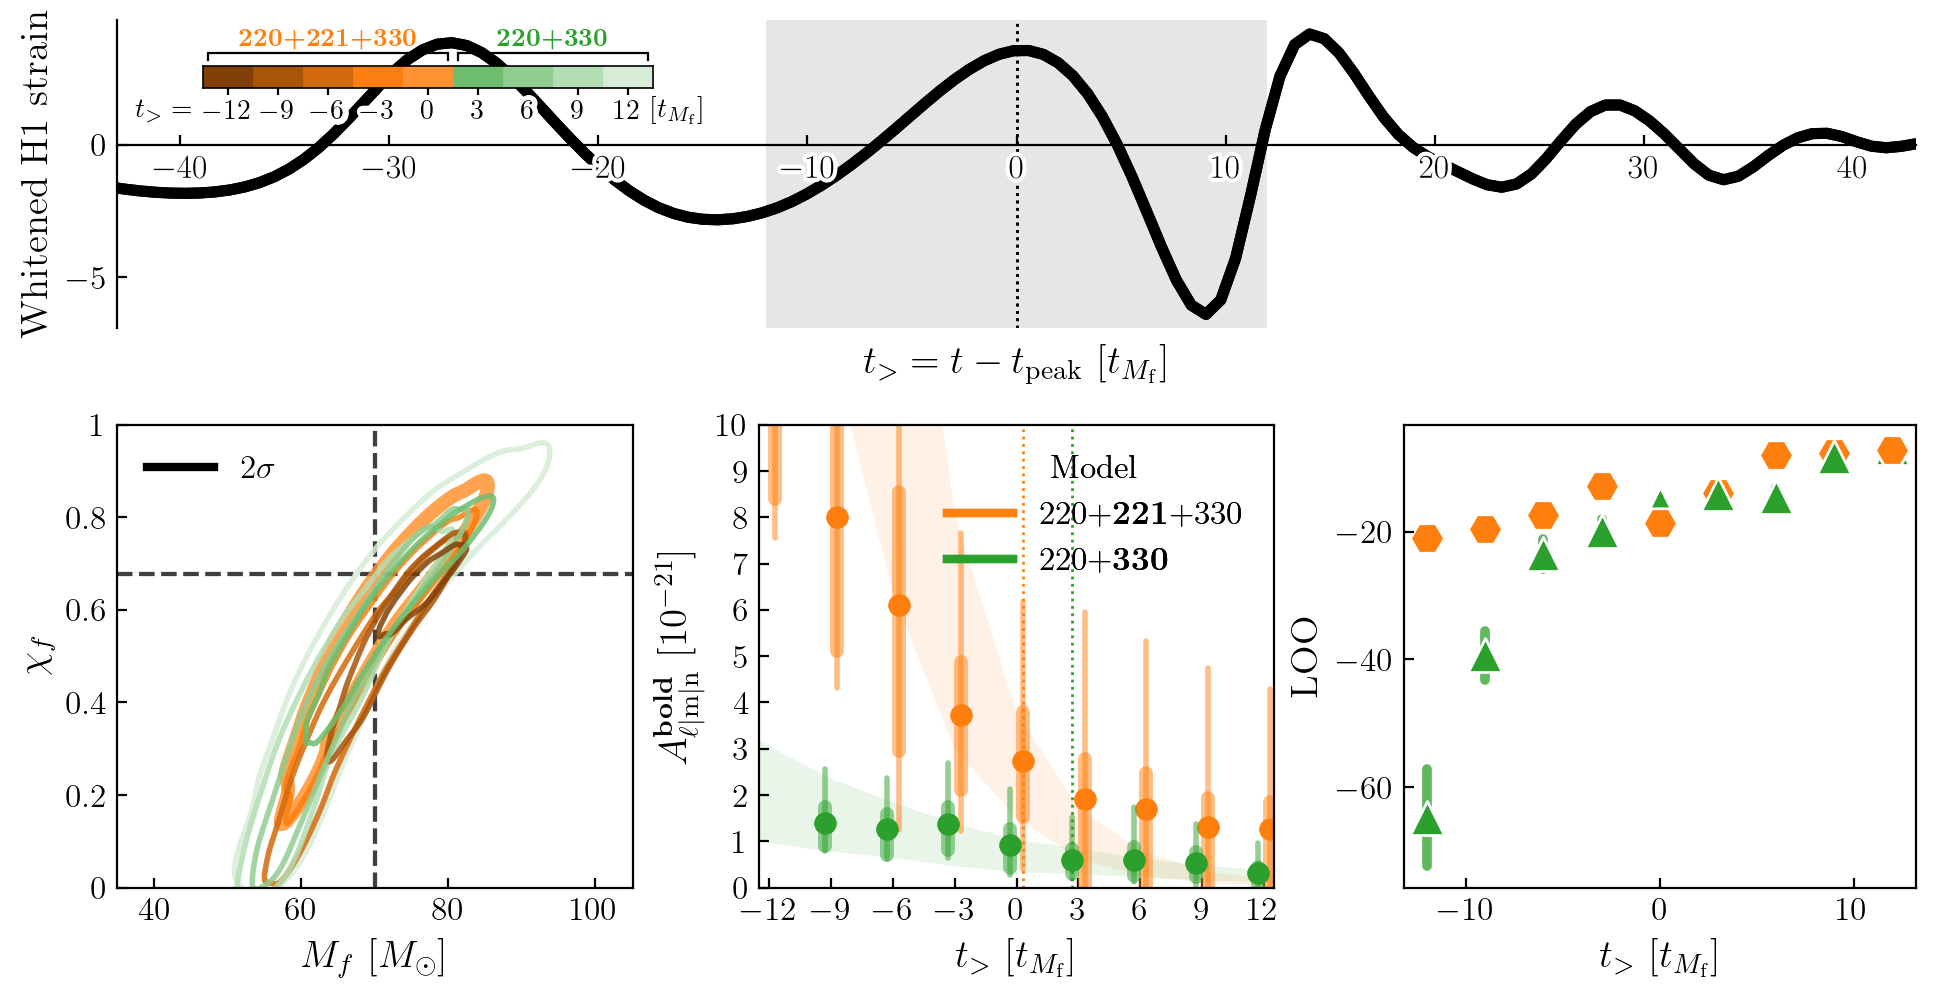

In [ ]:
fig, axs = main_combo('SXS_BBH_1156/mtot72', ['220', '221', '330'], fcut='>300', sub_hi=0, a_idx=[1], comp_model=['220+330'], cbar_kws=dict(cbar_bottom=0.35), save=False, **dict(shift=0.3, a_ylim=12, palette=['tab:orange', 'tab:green'], model_color='orange'))

fig1, axs1 = main_combo('SXS_BBH_1156/mtot72', ['220', '330'], fcut='>300', sub_lo=3, a_idx=[1], tref=3, comp=False, cbar_kws=dict(cbar_label='', cbar_bottom=0.2), figaxs=(fig, axs), **dict(shift=-0.3, a_ylim=12, leg_y=0.6, leg_title='', model_color='green'))

# axs1[0].plot(times, coll.idx[start].whitened_data[0], color='k', lw=1, ls=':')
# l, = axs1[0].plot(times, wmed, color='tab:orange')
# axs1[0].fill_between(times, 
#                       np.quantile(coll.idx[start].whitened_templates[0], 0.05, axis=-1),
#                       np.quantile(coll.idx[start].whitened_templates[0], 0.95, axis=-1), color=l.get_color(), alpha=0.2)

# starts = [-6, -3, 0]
# time_idx = coll.idx[-12].constant_data.time_index.values
# T = coll.idx[-12].config['target']['duration']
# times_s = (T / len(time_idx)) * time_idx

# for s in starts:
#     times = s + times_s / TM
#     l, = axs1[0].plot(times, np.quantile(coll.idx[s].whitened_residuals.stack(samp=['chain', 'draw']).values[0], 0.5, axis=-1))
#     # l, = plt.plot([], [])
#     axs1[0].fill_between(times, 
#                      np.quantile(coll.idx[s].whitened_residuals.stack(samp=['chain', 'draw']).values[0], 0.05, axis=-1),
#                      np.quantile(coll.idx[s].whitened_residuals.stack(samp=['chain', 'draw']).values[0], 0.95, axis=-1), color=l.get_color(), alpha=0.2)

fig.show()

results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot330/winj_ppSNR20_mtot330_inclined.pkl...
Plotting m-chi...
[-12.  -9.  -6.  -3.   0.   3.]
Plotting amps...
Plotting LOOs...
Adding 220+330 to model comparison...


results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached LOO results from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot330/comp/loo_comp_dict_ppSNR20_mtot330_inclined.pkl...


results:   0%|          | 0/9 [00:00<?, ?it/s]

results:   0%|          | 0/9 [00:00<?, ?it/s]

Loading cached whitened injection from /mnt/home/nkhusid/spec_inj/data/injections/SXS_BBH_1156/mtot330/winj_ppSNR20_mtot330_inclined.pkl...
Plotting m-chi...
[ 6.  9. 12.]
Plotting amps...


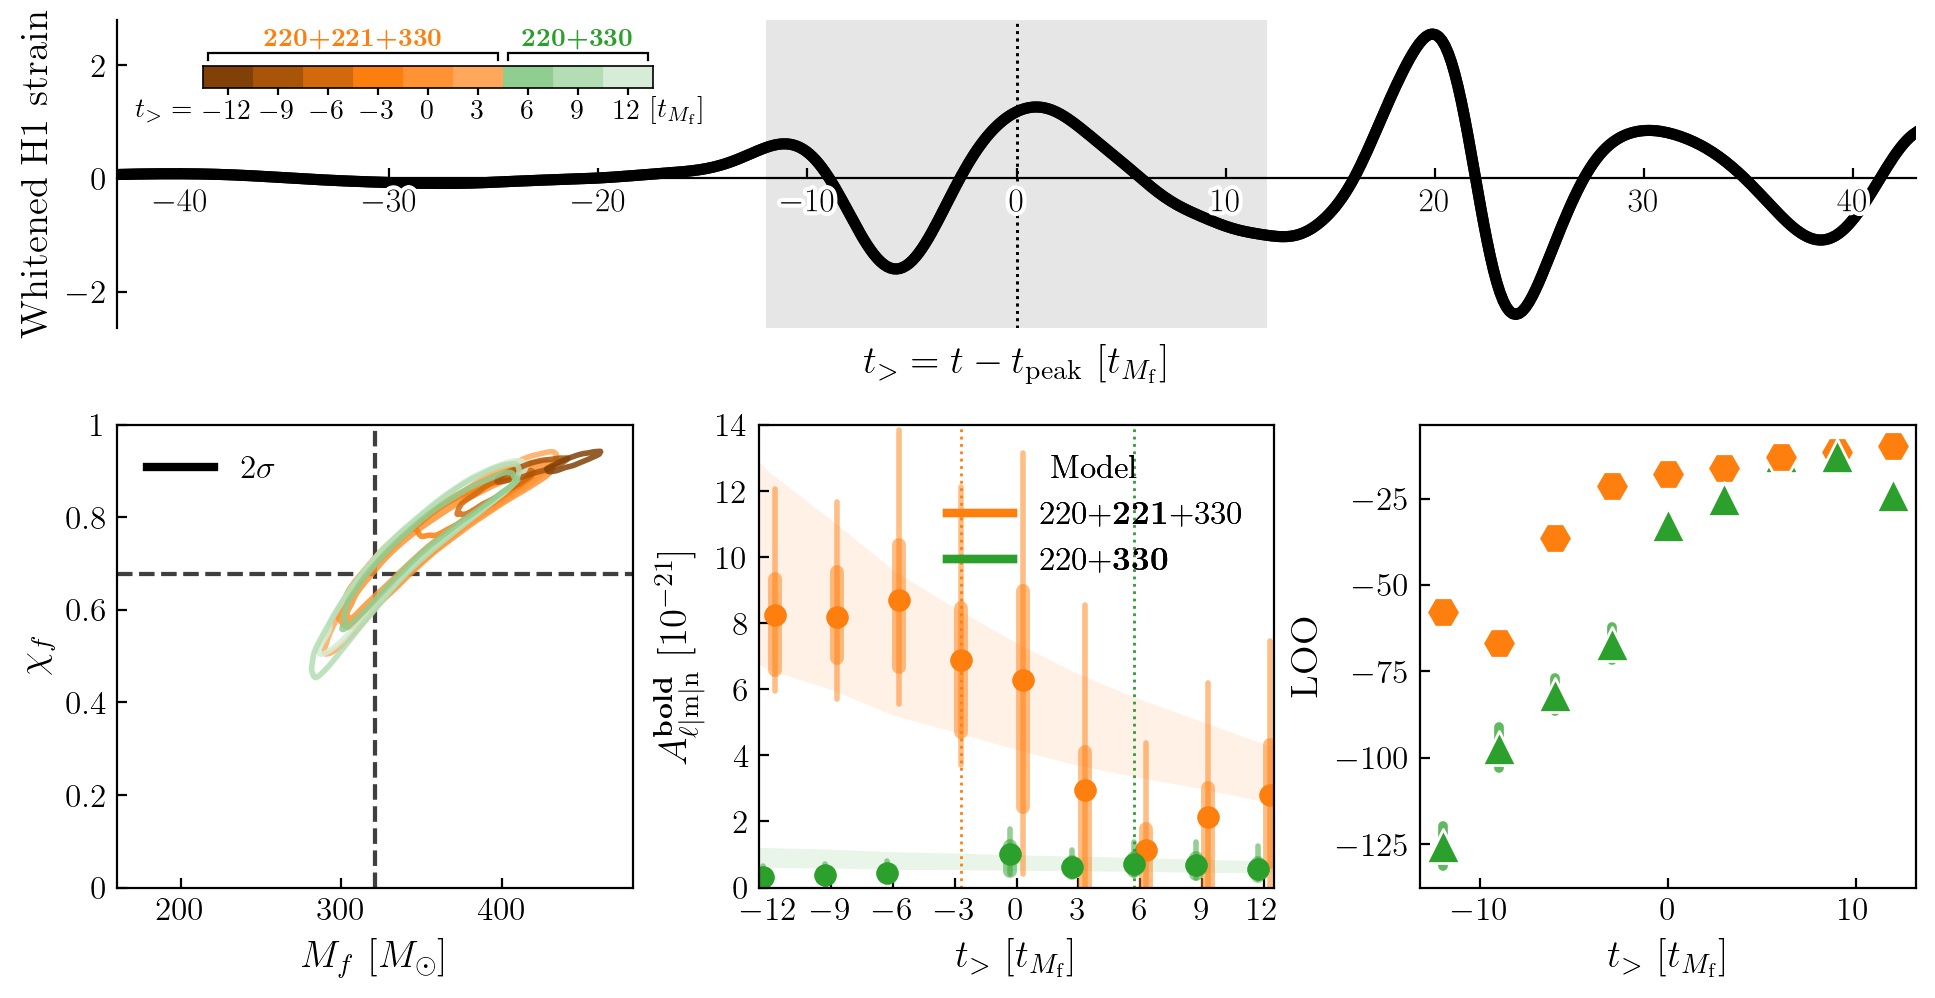

In [11]:
fig, axs = main_combo('SXS_BBH_1156/mtot330', ['220', '221', '330'], fcut='>70', sub_hi=3, a_idx=[1], tref=-3, comp_model=['220+330'], cbar_kws=dict(cbar_bottom=0.35), save=False, **dict(shift=0.3, a_ylim=14, palette=['tab:orange', 'tab:green'], model_color='orange', suffix=['_Mcut', '']))

_, _ = main_combo('SXS_BBH_1156/mtot330', ['220', '330'], fcut='>70', sub_lo=6, a_idx=[1], tref=6, comp=False, cbar_kws=dict(cbar_label='', cbar_bottom=0.2), figaxs=(fig, axs), **dict(shift=-0.3, a_ylim=14, leg_y=0.6, leg_title='', model_color='green', suffix=['_Mcut', '']))

fig.show()